# Plain MAP-Elites vs MAP-Elites + candidate-specific ROSARL (Safety-Gymnasium, QDax) — audited & corrected

**Research question.** Does replacing the reward of unsafe transitions with ROSARL's Minmax penalty,
estimated *independently for each candidate*, make MAP-Elites select safer policies than plain MAP-Elites?

**Six native tasks (safety-gymnasium 1.0.0):** `SafetyPointGoal1-v0`, `SafetyCarGoal1-v0`, `SafetyAntGoal1-v0`,
`SafetyAntVelocity-v1`, `SafetyHumanoidVelocity-v1`, `SafetyHalfCheetahVelocity-v1`.

**What the two arms share (by construction, and asserted in code):** the initial genotypes and their single
shared physical evaluation, network/controller, scene seeds, horizon, termination rule, emitter, grid,
behaviour descriptor and the *same* JAX PRNG key stream. **The only difference** is the fitness passed to QDax:

$$\text{ROSARL: } F_i=\tfrac1{|E_i|}\sum_{e\in E_i}\sum_t \tilde r_t,\quad
\tilde r_t=\begin{cases}R^{(i)}_{\rm minmax} & c_t>0\\ r_t & \text{otherwise}\end{cases}\qquad
\text{Plain: } F_i=\tfrac1{|E_i|}\sum_{e\in E_i}\sum_t r_t$$

$$R^{(i)}_{\rm minmax}=\min\!\big(R^{(i)}_{\min},\,V^{(i)}_{\min}-V^{(i)}_{\max}\big),$$
with bounds initialised at 0 and updated from candidate *i*'s **native** rewards $r_t$ and Monte-Carlo
returns-to-go $G_t$ (used as $V(s_t)$) only. $r_t$ and $c_t$ are the unmodified Safety-Gymnasium reward and cost.

**Unsafe semantics (both arms, all tasks):** a transition is unsafe iff the native cost is $>0$; it is recorded once
and the episode terminates immediately (absorbing unsafe state, as ROSARL assumes). For Safe Velocity this is a
deliberate change from the native continuing benchmark — see §12. A switch (`VELOCITY_UNSAFE_TERMINATION=False`)
exists only for a clearly labelled sensitivity analysis.

**Start with `PRESET='smoke'`** (plumbing only), then `pilot`, then `research` (multi-session, cached per task/seed).
Everything below the validation section reports what was *measured*; nothing is asserted from comments.

## 1. Host setup + isolated Python 3.10 MuJoCo worker
Colab installs the host dependencies automatically. Locally, the notebook creates the pinned worker environment on first run; set `SAFEQD_WORKER_PYTHON` to an existing Python 3.10 environment to manage it yourself. `SAFEQD_WORK_DIR` changes where the default worker and generated files are stored.

In [2]:
import os, sys, subprocess, shutil, sysconfig
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
print('Host Python:', sys.version.split()[0], '| Colab:', IN_COLAB)
# Host (Colab Python) runs QDax/JAX. MuJoCo + safety-gymnasium==1.0.0 need Python 3.10 and
# old pins, so they run in an isolated uv virtual environment ("worker").
WORK_DIR = Path(os.environ.get('SAFEQD_WORK_DIR', '/content' if IN_COLAB else Path.cwd() / 'safeqd_work'))
WORK_DIR.mkdir(parents=True, exist_ok=True)
default_worker = WORK_DIR / 'safe_qd_py310' / ('Scripts/python.exe' if os.name == 'nt' else 'bin/python')
WORKER_PYTHON = Path(os.environ.get('SAFEQD_WORKER_PYTHON', default_worker))


def sh(*cmd):
    """Run a command; on failure show its real stdout/stderr (not just the exit status)."""
    print('$', ' '.join(map(str, cmd)))
    r = subprocess.run([str(c) for c in cmd], capture_output=True, text=True)
    if r.returncode:
        print(r.stdout[-4000:])
        print(r.stderr[-4000:])
        raise RuntimeError(f'Command failed (exit {r.returncode}): {" ".join(map(str, cmd))}')
    if r.stdout.strip():
        print(r.stdout[-1500:])


if IN_COLAB:
    # No numpy pin: Colab's Python 3.13 has no numpy<2 wheels, and the host side (QDax/JAX) does not need one.
    # The MuJoCo worker below has its own isolated Python 3.10 environment with its own numpy pin.
    sh(sys.executable, '-m', 'pip', 'install', '-q', 'qdax==0.5.0', 'uv>=0.8', 'matplotlib', 'pandas', 'scipy')

if not WORKER_PYTHON.is_file():
    if 'SAFEQD_WORKER_PYTHON' in os.environ:
        raise FileNotFoundError(
            f"Configured worker interpreter not found: {WORKER_PYTHON}. "
            "Set SAFEQD_WORKER_PYTHON to an existing Python 3.10 interpreter, or unset it to create the default worker."
        )
    uv = shutil.which('uv')
    if not uv:
        sh(sys.executable, '-m', 'pip', 'install', '-q', 'uv>=0.8')
        uv_name = 'uv.exe' if os.name == 'nt' else 'uv'
        uv = str(Path(sysconfig.get_path('scripts')) / uv_name)
        if not Path(uv).is_file():
            raise FileNotFoundError(f'uv was installed but its executable was not found: {uv}')
    sh(uv, 'python', 'install', '3.10')
    sh(uv, 'venv', '--python', '3.10', WORK_DIR / 'safe_qd_py310')
    sh(uv, 'pip', 'install', '--python', WORKER_PYTHON, '--only-binary', ':all:',
       'numpy==1.23.5', 'gymnasium==0.28.1', 'gymnasium-robotics==1.2.2', 'mujoco==2.3.3',
       'pygame==2.1.0', 'safety-gymnasium==1.0.0', 'xmltodict>=0.13', 'PyYAML>=6.0')
    sh(uv, 'pip', 'check', '--python', WORKER_PYTHON)
elif IN_COLAB:
    sh('uv', 'pip', 'check', '--python', WORKER_PYTHON)

if not WORKER_PYTHON.is_file():
    raise FileNotFoundError(f'Worker interpreter missing after setup: {WORKER_PYTHON}')
os.environ.setdefault('MUJOCO_GL', 'egl' if IN_COLAB else 'glfw')


Host Python: 3.11.9 | Colab: False
$ c:\Users\mthom\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\Scripts\uv.EXE python install 3.10
$ c:\Users\mthom\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\Scripts\uv.EXE venv --python 3.10 c:\Users\mthom\Downloads\Claude_Pro_Project\qdax_rosarl_audit\safeqd_work\safe_qd_py310
$ c:\Users\mthom\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\Scripts\uv.EXE pip install --python c:\Users\mthom\Downloads\Claude_Pro_Project\qdax_rosarl_audit\safeqd_work\safe_qd_py310\Scripts\python.exe --only-binary :all: numpy==1.23.5 gymnasium==0.28.1 gymnasium-robotics==1.2.2 mujoco==2.3.3 pygame==2.1.0 safety-gymnasium==1.0.0 xmltodict>=0.13 PyYAML>=6.0
$ c:\Users\mthom\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311

'glfw'

## 2. Tasks, methods, presets
Override without editing: `SAFEQD_PRESET`, `SAFEQD_TASKS`, `SAFEQD_SEEDS`, `SAFEQD_WORKERS`.

In [3]:
import json, secrets, time, pickle, functools, traceback
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
from qdax.core.map_elites import MAPElites
from qdax.core.containers.mapelites_repertoire import MapElitesRepertoire, compute_euclidean_centroids
from qdax.core.emitters.mutation_operators import isoline_variation
from qdax.core.emitters.standard_emitters import MixingEmitter

TASKS = {
    'Point Navigation': ('navigation', 'SafetyPointGoal1-v0', 'point'),
    'Car Navigation': ('navigation', 'SafetyCarGoal1-v0', 'car'),
    'Ant Navigation': ('navigation', 'SafetyAntGoal1-v0', 'ant'),
    'Ant SafeVelocity': ('velocity', 'SafetyAntVelocity-v1', 'ant'),
    'Humanoid SafeVelocity': ('velocity', 'SafetyHumanoidVelocity-v1', 'humanoid'),
    'HalfCheetah SafeVelocity': ('velocity', 'SafetyHalfCheetahVelocity-v1', 'halfcheetah'),
}
METHODS = ('MAP-Elites + ROSARL', 'Plain MAP-Elites')

# Presets (per task, per arm). Budgets were sized from measured single-process throughput
# (navigation ~400-650 steps/s (no model cache), Ant/Humanoid ~800-1300, HalfCheetah ~2500).
PRESETS = {
    # Plumbing only: proves the pipeline end-to-end. NOT evidence about either method.
    'smoke': dict(generations=3, population=6, train_scenes=2, validation_scenes=2, heldout_scenes=4,
                  horizon=100, bootstrap_rounds=1, eval_every=1, final_top_k=2, seeds=[1]),
    # Pilot: enough generations to see whether learning curves move (several hours for all six tasks x 3 seeds).
    # A 3-seed audit pilot with 3 training layouts showed champions colliding in ~50% of UNSEEN
    # Point layouts for both arms (layout over-fitting) -> more training layouts per evaluation.
    'pilot': dict(generations=30, population=24, train_scenes=5, validation_scenes=6, heldout_scenes=12,
                  horizon=300, bootstrap_rounds=2, eval_every=5, final_top_k=4, seeds=[1, 2, 3]),
    # Research: >=5 seeds for uncertainty. Needs several Colab sessions -> results are cached
    # per (task, seed) in RESULTS_DIR and resumed automatically.
    'research': dict(generations=100, population=32, train_scenes=8, validation_scenes=8,
                     heldout_scenes=32, horizon=500, bootstrap_rounds=3, eval_every=10,
                     final_top_k=5, seeds=[1, 2, 3, 4, 5]),
}
PRESET = os.environ.get('SAFEQD_PRESET', 'smoke')
CFG = dict(PRESETS[PRESET])
CFG.update(json.loads(os.environ.get('SAFEQD_CFG_JSON', '{}')))   # e.g. '{"generations": 20}'
RUN_SEEDS = [int(s) for s in os.environ['SAFEQD_SEEDS'].split(',')] if os.environ.get('SAFEQD_SEEDS') else CFG['seeds']
RUN_TASKS = os.environ['SAFEQD_TASKS'].split(',') if os.environ.get('SAFEQD_TASKS') else list(TASKS)
assert set(RUN_TASKS) <= set(TASKS)
N_WORKERS = int(os.environ.get('SAFEQD_WORKERS', max(1, min(4, (os.cpu_count() or 2)))))
HIDDEN = (32, 32)
GRID = (10, 10)
ISO_SIGMA = .08
LINE_SIGMA = .15
# ROSARL assumes unsafe states are absorbing. Velocity tasks therefore terminate at the first
# native speed-limit violation, for BOTH arms. Set False only for the clearly labelled
# continuing-task sensitivity analysis (ROSARL's guarantees then do not apply).
VELOCITY_UNSAFE_TERMINATION = True
RESULTS_DIR = WORK_DIR / f'safe_qd_results_{PRESET}'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
TEST_RESULTS = []   # rows: section, test, task, status (PASS/FAIL/NOT TESTED/INFO), evidence


def record(section, test, ok, evidence='', task='-', status=None):
    status = status or ('PASS' if ok else 'FAIL')
    TEST_RESULTS.append(dict(section=section, test=test, task=task, status=status, evidence=str(evidence)))
    print(f'[{status:4}] {section} | {task} | {test} | {evidence}')
    return ok


def param_count(obs_dim, action_dim):
    dims = (obs_dim, *HIDDEN, action_dim)
    return sum((a + 1) * b for a, b in zip(dims[:-1], dims[1:])) + 2 * action_dim + 1


print(f'PRESET={PRESET} {CFG} | tasks={RUN_TASKS} | seeds={RUN_SEEDS} | workers/task={N_WORKERS}')


PRESET=smoke {'generations': 3, 'population': 6, 'train_scenes': 2, 'validation_scenes': 2, 'heldout_scenes': 4, 'horizon': 100, 'bootstrap_rounds': 1, 'eval_every': 1, 'final_top_k': 2, 'seeds': [1]} | tasks=['Point Navigation', 'Car Navigation', 'Ant Navigation', 'Ant SafeVelocity', 'Humanoid SafeVelocity', 'HalfCheetah SafeVelocity'] | seeds=[1] | workers/task=4


## 3. Native Safety-Gymnasium worker (Python 3.10)
Key corrections vs. the original: native reward only (the original added a hand-crafted `−1` collision term);
native `goal_met`; velocity speed limit read from the env (HalfCheetah's cost uses **signed** x-velocity);
measured Car drive axis (the Car drives along its body **−y** axis — the original used body +x, so its
"forward" probe measured noise and the goal-heading prior steered ~90° off); Point turn sign measured;
unsafe termination for every task. (No compiled-model cache is used: it grew without bound in RAM on Colab, so every reset recompiles the world XML — slower navigation resets, but flat memory.)

In [4]:
WORKER_SCRIPT = WORK_DIR / 'safe_qd_worker.py'
WORKER_SOURCE = r'''"""Native Safety-Gymnasium worker for the two-method MAP-Elites study (Python 3.10).

Episode semantics (identical for both MAP-Elites arms):
  1. the policy emits an action for the current state;
  2. the native environment steps once and returns (reward, cost);
  3. the native cost alone decides whether the transition is unsafe (cost > 0);
  4. the transition is recorded exactly once (native reward + native cost);
  5. if unsafe and `terminate_on_unsafe`, the episode ends immediately; no later
     action, reward or cost is recorded.
The worker never modifies the reward. ROSARL replacement happens on the host and only
for the ROSARL arm; the worker always returns native rewards and native costs.
"""
import json
import sys
import traceback

import numpy as np
import safety_gymnasium
from gymnasium.spaces.utils import flatten

PREFIX = 'SAFEQD:'
ENV_IDS = {
    'Point Navigation': ('navigation', 'SafetyPointGoal1-v0', 'point'),
    'Car Navigation': ('navigation', 'SafetyCarGoal1-v0', 'car'),
    'Ant Navigation': ('navigation', 'SafetyAntGoal1-v0', 'ant'),
    'Ant SafeVelocity': ('velocity', 'SafetyAntVelocity-v1', 'ant'),
    'Humanoid SafeVelocity': ('velocity', 'SafetyHumanoidVelocity-v1', 'humanoid'),
    'HalfCheetah SafeVelocity': ('velocity', 'SafetyHalfCheetahVelocity-v1', 'halfcheetah'),
}
# Residual authority of the evolved network relative to the shared goal-heading prior.
# 1.0 lets the network fully cancel / reverse the prior (needed to steer around hazards).
NAV_RESIDUAL_GAIN = 1.0
# Body-frame unit vector along which the robot actually drives; set by calibrate_drive().
DRIVE_AXIS_BODY = np.array([1.0, 0.0])


def send(payload):
    print(PREFIX + json.dumps(payload, allow_nan=False), flush=True)


def get_task(env):
    base = env.unwrapped
    return getattr(base, 'task', base)


def flat_observation(env, obs):
    if isinstance(obs, dict):
        return np.asarray(flatten(env.observation_space, obs), dtype=np.float32).reshape(-1)
    return np.asarray(obs, dtype=np.float32).reshape(-1)


def native_speed_limit(env, kind):
    if kind != 'velocity':
        return None
    return float(env.unwrapped._velocity_threshold)


def world_geometry(env):
    task = get_task(env)
    p = np.asarray(task.hazards.pos, dtype=np.float64)
    return {'goal': np.asarray(task.goal.pos[:2], dtype=np.float64).tolist(),
            'radius': float(task.goal.size),
            'hazard_radius': float(task.hazards.size),
            'hazards': p.reshape(-1, p.shape[-1])[:, :2].tolist()}


def physical_state(env, kind, robot, info=None):
    """Position, unit heading and planar velocity, copied out of MuJoCo buffers."""
    if kind == 'navigation':
        agent = get_task(env).agent
        pos = np.array(agent.pos[:2], dtype=np.float64, copy=True)
        rot = np.asarray(agent.mat, dtype=np.float64).reshape(3, 3)
        vel = np.array(agent.vel[:2], dtype=np.float64, copy=True)
        # Measured drive axis in the body frame (body +x for Point/Ant, body -y for Car).
        forward = rot[:2, :2] @ DRIVE_AXIS_BODY
    else:
        data = env.unwrapped.data
        if robot == 'halfcheetah':
            pos = np.array([float(data.qpos[0]), 0.0])
            vel = np.array([float(data.qvel[0]), 0.0])
        else:
            pos = np.asarray(data.qpos[:2], dtype=np.float64).copy()
            vel = np.asarray(data.qvel[:2], dtype=np.float64).copy()
        if info is not None and 'x_velocity' in info:
            # The exact finite-difference velocity the native cost is computed from.
            vel = np.array([float(info['x_velocity']), float(info.get('y_velocity', 0.0))])
        forward = np.array([1.0, 0.0])
    scale = max(np.linalg.norm(forward), 1e-9)
    return pos, forward / scale, vel


def cost_speed(robot, velocity):
    """Speed quantity that the native Safe Velocity cost thresholds.

    HalfCheetah: signed x-velocity. Ant / Humanoid: planar speed norm.
    """
    if robot == 'halfcheetah':
        return float(velocity[0])
    return float(np.linalg.norm(velocity[:2]))


def signed_angle(vec_from, vec_to):
    return float(np.arctan2(vec_from[0] * vec_to[1] - vec_from[1] * vec_to[0],
                            np.dot(vec_from, vec_to)))


def calibrate_drive(env, robot):
    """Measure, on real physics, the body-frame drive axis and the turn command sign.

    Car: action (left, right) wheel torques; Point: action (forward motor, rotation).
    Sets DRIVE_AXIS_BODY so that the commanded "drive" action moves along +heading.
    """
    global DRIVE_AXIS_BODY
    drive_cmd = [1.0, 1.0] if robot == 'car' else [1.0, 0.0]
    turn_cmd = [1.0, -1.0] if robot == 'car' else [0.0, 1.0]

    def probe(action, steps=50):
        env.reset(seed=7421)
        agent = get_task(env).agent
        p0 = np.array(agent.pos[:2], dtype=np.float64)
        r0 = np.asarray(agent.mat, dtype=np.float64).reshape(3, 3)[:2, :2]
        for _ in range(steps):
            _, _, _, terminated, truncated, _ = env.step(np.asarray(action, dtype=np.float32))
            if terminated or truncated:
                break
        p1 = np.array(agent.pos[:2], dtype=np.float64)
        r1 = np.asarray(agent.mat, dtype=np.float64).reshape(3, 3)[:2, :2]
        return r0.T @ (p1 - p0), signed_angle(r0[:, 0], r1[:, 0])

    body_disp, _ = probe(drive_cmd)
    if np.linalg.norm(body_disp) < 0.05:
        raise RuntimeError(f'{robot}: drive probe moved only {np.linalg.norm(body_disp):.4f} m')
    DRIVE_AXIS_BODY = body_disp / np.linalg.norm(body_disp)
    _, yaw = probe(turn_cmd)
    if abs(yaw) < 0.1:
        raise RuntimeError(f'{robot}: turn probe rotated only {yaw:.4f} rad')
    return {'robot': robot, 'drive_axis_body': DRIVE_AXIS_BODY.tolist(),
            'drive_probe_m': float(np.linalg.norm(body_disp)),
            'turn_probe_rad': float(yaw), 'turn_sign': 1.0 if yaw > 0 else -1.0}


def feature_vector(env, obs, pos, heading, velocity, kind, goal, d0, robot, t, speed_limit):
    base = np.tanh(flat_observation(env, obs) / 10.0)
    side = np.array([-heading[1], heading[0]])
    local_v = np.array([np.dot(velocity, heading), np.dot(velocity, side)]) / 4.0
    if kind == 'navigation':
        difference = goal - pos
        relative = np.array([np.dot(difference, heading), np.dot(difference, side)]) / max(d0, 1e-8)
        magnitude = np.linalg.norm(difference) / max(d0, 1e-8)
    else:
        relative = np.zeros(2)
        magnitude = cost_speed(robot, velocity) / speed_limit
    clock = 2.0 * np.pi * t / 20.0
    return np.concatenate([base, np.clip(relative, -3, 3),
                           np.array([np.clip(magnitude, -10, 10)]),
                           np.clip(local_v, -3, 3),
                           np.array([np.sin(clock), np.cos(clock)])]).astype(np.float32)


def policy_parameter_count(dim_obs, dim_action, hidden):
    shape = (dim_obs, *hidden, dim_action)
    return sum((a + 1) * b for a, b in zip(shape[:-1], shape[1:])) + 2 * dim_action + 1


def normalized_policy(genome, features, action_dim, hidden, t, kind, robot, goal, pos, heading,
                      calibration, motor_mode='prior'):
    """Return an action in [-1, 1]^action_dim (later mapped affinely to the native box)."""
    dims = (len(features), *hidden, action_dim)
    if len(genome) != policy_parameter_count(len(features), action_dim, hidden):
        raise ValueError('Genome dimensions mismatch')
    idx = 0
    x = np.asarray(features, dtype=np.float32)
    for n_in, n_out in zip(dims[:-1], dims[1:]):
        matrix = genome[idx:idx + n_in * n_out].reshape(n_in, n_out) / np.sqrt(n_in)
        idx += n_in * n_out
        bias = genome[idx:idx + n_out]
        idx += n_out
        x = np.tanh(x @ matrix + bias)
    residual = x
    if motor_mode == 'naive':
        return np.clip(residual, -1., 1.)
    osc_amp = 1.0 / (1.0 + np.exp(-np.clip(genome[idx:idx + action_dim], -10, 10)))
    idx += action_dim
    osc_phase = genome[idx:idx + action_dim]
    idx += action_dim
    frequency_gene = genome[idx]
    # Shared by both arms; uses no hazard / cost information.
    if kind == 'navigation' and robot in ('car', 'point'):
        angle = signed_angle(heading, goal - pos)
        turn = float(np.clip(angle / (np.pi / 2), -1.0, 1.0))
        # turn > 0: goal is counter-clockwise of the drive axis; turn_sign maps that to the
        # actuator command measured to rotate the robot counter-clockwise.
        steer = calibration['turn_sign'] * turn
        if robot == 'car':
            speed = 0.60 if abs(angle) < 1.4 else 0.25
            prior = np.array([speed + 0.53 * steer, speed - 0.53 * steer])
        else:
            prior = np.array([0.75 if abs(angle) < 1.2 else 0.35, np.clip(1.5 * steer, -1, 1)])
        action = prior + NAV_RESIDUAL_GAIN * residual
    else:
        freq = 0.025 + 0.09 / (1.0 + np.exp(-np.clip(frequency_gene, -8, 8)))
        leg_ix = np.arange(action_dim)
        if robot == 'ant' and action_dim == 8:
            pattern = np.array([0, .5, .5, 0])[leg_ix // 2] + (leg_ix % 2) * 0.25
        else:
            pattern = ((leg_ix % 2) * .5 + (leg_ix // 2 % 2) * .25)
        wave = np.sin(2 * np.pi * (freq * t + pattern + .35 * osc_phase))
        action = 0.95 * osc_amp * wave + 0.65 * residual
    return np.clip(action, -1., 1.)


def run_episode(env, kind, robot, seed, horizon, terminate_on_unsafe, speed_limit, act_fn,
                hazard_size_override=None):
    """One episode. `act_fn(t, state_dict) -> action in [-1,1]`. Returns a JSON-safe dict."""
    low = np.asarray(env.action_space.low, dtype=np.float64).reshape(-1)
    high = np.asarray(env.action_space.high, dtype=np.float64).reshape(-1)
    obs, info = env.reset(seed=int(seed))
    task = get_task(env) if kind == 'navigation' else None
    saved_size = None
    if hazard_size_override is not None:  # test hook: enlarge hazards AFTER the safe reset
        saved_size = task.hazards.size
        task.hazards.size = float(hazard_size_override)
    try:
        geometry = world_geometry(env) if kind == 'navigation' else {}
        pos, heading, velocity = physical_state(env, kind, robot, info)
        initial = pos.copy()
        goal = np.asarray(geometry.get('goal', [0, 0]), dtype=np.float64)
        d0 = float(np.linalg.norm(goal - pos)) if kind == 'navigation' else 0.0
        rewards, costs, speeds, abs_actions, own_progress = [], [], [], [], []
        walked = 0.0
        success = False
        goal_met_any = False
        reason = 'horizon'
        for t in range(int(horizon)):
            state = dict(obs=obs, pos=pos, heading=heading, velocity=velocity, goal=goal, d0=d0, t=t)
            act = np.clip(np.asarray(act_fn(t, state), dtype=np.float64).reshape(-1), -1.0, 1.0)
            abs_actions.append(float(np.mean(np.abs(act))))
            action = ((act + 1.0) / 2.0 * (high - low) + low).reshape(env.action_space.shape)
            old_pos = pos.copy()
            obs, native_reward, native_cost, terminated, truncated, info = env.step(action)
            pos, heading, velocity = physical_state(env, kind, robot, info)
            reward = float(np.asarray(native_reward).sum())
            cost = float(np.asarray(native_cost).sum())
            if not np.isfinite(reward) or not np.isfinite(cost) or not np.all(np.isfinite(pos)):
                raise RuntimeError(f'Non-finite native reward/cost/state on {robot}/{kind}')
            unsafe = cost > 0.0
            rewards.append(reward)
            costs.append(cost)
            walked += float(np.linalg.norm(pos - old_pos))
            if kind == 'navigation':
                own_progress.append(float(np.linalg.norm(goal - old_pos) - np.linalg.norm(goal - pos)))
                speeds.append(float(np.linalg.norm(velocity)))
            else:
                speeds.append(cost_speed(robot, velocity))
            goal_met = bool(info.get('goal_met', False)) if kind == 'navigation' else False
            goal_met_any = goal_met_any or goal_met
            if unsafe and terminate_on_unsafe:
                reason = 'unsafe'
                break
            if goal_met:
                success = not unsafe
                reason = 'goal'
                break
            if terminated:
                reason = 'native_terminal'
                break
            if truncated:
                reason = 'native_truncation'
                break
        unsafe_flags = [c > 0 for c in costs]
        if kind == 'navigation':
            final_distance = float(np.linalg.norm(goal - pos))
            progress = d0 - final_distance
            hazard_min = float(min(np.linalg.norm(np.asarray(h) - pos) for h in geometry['hazards']))
        else:
            final_distance = None
            progress = float(pos[0] - initial[0])
            hazard_min = None
        return {'rewards': rewards, 'costs': costs, 'steps': len(rewards),
                'return_raw': float(np.sum(rewards)), 'cost_total': float(np.sum(costs)),
                'unsafe_steps': int(np.sum(unsafe_flags)), 'unsafe': bool(any(unsafe_flags)),
                'first_unsafe_step': (int(np.argmax(unsafe_flags)) if any(unsafe_flags) else None),
                'success': bool(success), 'goal_met': bool(goal_met_any), 'safe_fraction': float(np.mean(np.logical_not(unsafe_flags))),
                'net_displacement': float(np.linalg.norm(pos - initial)), 'path_length': walked,
                'progress': float(progress), 'initial_distance': (d0 if kind == 'navigation' else None),
                'final_distance': final_distance, 'own_progress_sum': float(np.sum(own_progress)),
                'mean_speed': float(np.mean(speeds)), 'max_speed': float(np.max(speeds)),
                'speed_limit': speed_limit, 'mean_abs_action': float(np.mean(abs_actions)),
                'final_hazard_distance': hazard_min, 'reason': reason, 'scene_seed': int(seed),
                'terminate_on_unsafe': bool(terminate_on_unsafe)}
    finally:
        if saved_size is not None:
            task.hazards.size = saved_size


def evaluate_batch(env, kind, robot, genomes, seeds, hidden, horizon, calibration, speed_limit,
                   terminate_on_unsafe, motor_mode='prior'):
    matrix = np.asarray(genomes, dtype=np.float32)
    if matrix.ndim != 2:
        raise ValueError('Expected population by parameter matrix')
    action_dim = int(np.prod(env.action_space.shape))
    results = []
    for genome in matrix:
        def act_fn(t, s, genome=genome):
            features = feature_vector(env, s['obs'], s['pos'], s['heading'], s['velocity'], kind,
                                      s['goal'], s['d0'], robot, t, speed_limit or 1.0)
            return normalized_policy(genome, features, action_dim, hidden, t, kind, robot,
                                     s['goal'], s['pos'], s['heading'], calibration, motor_mode)
        results.append([run_episode(env, kind, robot, seed, horizon, terminate_on_unsafe,
                                    speed_limit, act_fn) for seed in seeds])
    return results


def scripted_episode(env, kind, robot, msg, speed_limit):
    """Test hook: constant action, optional hazard enlargement / speed-limit override."""
    const = np.asarray(msg['action'], dtype=np.float64)
    base = env.unwrapped
    saved = None
    if msg.get('speed_limit_override') is not None:
        saved = base._velocity_threshold
        base._velocity_threshold = float(msg['speed_limit_override'])
    try:
        return run_episode(env, kind, robot, msg['seed'], msg['horizon'], msg['terminate_on_unsafe'],
                           speed_limit, lambda t, s: const,
                           hazard_size_override=msg.get('hazard_size_override'))
    finally:
        if saved is not None:
            base._velocity_threshold = saved


def reset_signature(env, kind, robot, seed):
    obs, info = env.reset(seed=int(seed))
    sig = {'obs': flat_observation(env, obs).round(6).tolist()}
    if kind == 'navigation':
        sig.update(world_geometry(env))
        sig['agent'] = np.round(get_task(env).agent.pos[:2], 6).tolist()
    return sig


def main():
    name = sys.argv[1]
    kind, env_id, robot = ENV_IDS[name]
    env = safety_gymnasium.make(env_id)
    if kind == 'navigation':
        # A reached goal ends the episode (no resampled second goal).
        get_task(env).mechanism_conf.continue_goal = False
    calibration = calibrate_drive(env, robot) if kind == 'navigation' and robot in ('car', 'point') else {
        'robot': robot, 'drive_axis_body': [1.0, 0.0], 'turn_sign': 1.0}
    speed_limit = native_speed_limit(env, kind)
    obs, info = env.reset(seed=713)
    raw_dim = len(flat_observation(env, obs))
    action_dim = int(np.prod(env.action_space.shape))
    send({'ok': True, 'id': env_id, 'kind': kind, 'robot': robot, 'raw_dim': raw_dim,
          'action_dim': action_dim, 'feature_dim': raw_dim + 7,
          'action_low': np.asarray(env.action_space.low).tolist(),
          'action_high': np.asarray(env.action_space.high).tolist(),
          'speed_limit': speed_limit, 'max_episode_steps': getattr(env.spec, 'max_episode_steps', None),
          'calibration': calibration, 'model_cache': False, 'safety_gymnasium': getattr(safety_gymnasium, '__version__', '?')})
    try:
        for line in sys.stdin:
            try:
                msg = json.loads(line)
                op = msg['op']
                if op == 'close':
                    send({'ok': True})
                    break
                if op == 'rollout':
                    eps = evaluate_batch(env, kind, robot, msg['genomes'], msg['seeds'], msg['hidden'],
                                         msg['horizon'], calibration, speed_limit,
                                         bool(msg['terminate_on_unsafe']), msg.get('motor_mode', 'prior'))
                    send({'ok': True, 'episodes': eps})
                elif op == 'scripted':
                    send({'ok': True, 'episode': scripted_episode(env, kind, robot, msg, speed_limit)})
                elif op == 'reset_signature':
                    send({'ok': True, 'signature': reset_signature(env, kind, robot, msg['seed'])})
                else:
                    raise ValueError('Unsupported worker command: ' + str(op))
            except Exception:
                send({'ok': False, 'error': traceback.format_exc()})
    finally:
        env.close()


if __name__ == '__main__':
    try:
        main()
    except Exception:
        send({'ok': False, 'error': traceback.format_exc()})
        raise
'''
WORKER_SCRIPT.write_text(WORKER_SOURCE, encoding='utf-8')
compile(WORKER_SOURCE, str(WORKER_SCRIPT), 'exec')
print('Wrote native worker:', WORKER_SCRIPT)


Wrote native worker: c:\Users\mthom\Downloads\Claude_Pro_Project\qdax_rosarl_audit\safeqd_work\safe_qd_worker.py


## 4. Worker pool and per-episode invariants
Every real episode is checked: transition counts, a single terminal unsafe transition, no post-terminal data, and (navigation) native reward = distance progress + goal bonus.

In [5]:
class NativeWorker:
    """One Python-3.10 Safety-Gymnasium process speaking line-delimited JSON."""

    def __init__(self, name):
        assert name in TASKS
        self.name = name
        self.kind, self.native_id, self.robot = TASKS[name]
        self.log_path = WORK_DIR / f'safe_qd_{self.robot}_{secrets.token_hex(4)}.log'
        self.log = self.log_path.open('w', encoding='utf-8')
        self.process = subprocess.Popen([str(WORKER_PYTHON), str(WORKER_SCRIPT), name],
                                        stdin=subprocess.PIPE, stdout=subprocess.PIPE, stderr=self.log,
                                        text=True, bufsize=1, env=os.environ.copy())
        try:
            self.meta = self._receive()
        except Exception:
            self.close(force=True)
            raise

    def _receive(self):
        while True:
            line = self.process.stdout.readline()
            if not line:
                self.log.flush()
                raise RuntimeError(f'Worker exited ({self.process.poll()}); stderr at {self.log_path}: '
                                   + self.log_path.read_text(errors='replace')[-3500:])
            if line.startswith('SAFEQD:'):
                payload = json.loads(line[len('SAFEQD:'):])
                if not payload.get('ok'):
                    raise RuntimeError(payload.get('error', 'Unknown worker failure'))
                return payload

    def send(self, payload):
        self.process.stdin.write(json.dumps(payload) + '\n')
        self.process.stdin.flush()

    def request(self, payload):
        self.send(payload)
        return self._receive()

    def close(self, force=False):
        proc = getattr(self, 'process', None)
        if proc is not None:
            if proc.poll() is None:
                if not force:
                    try:
                        self.send({'op': 'close'})
                    except Exception:
                        pass
                try:
                    proc.wait(timeout=10)
                except subprocess.TimeoutExpired:
                    proc.kill()
                    proc.wait()
            for stream in (proc.stdin, proc.stdout):
                if stream:
                    stream.close()
        if hasattr(self, 'log') and not self.log.closed:
            self.log.close()


def check_episode_invariants(ep, kind, terminate_on_unsafe):
    """Termination / accounting invariants, enforced on EVERY real episode."""
    n = ep['steps']
    assert len(ep['rewards']) == len(ep['costs']) == n >= 1, 'transition count mismatch'
    unsafe = [c > 0 for c in ep['costs']]
    assert ep['unsafe_steps'] == sum(unsafe)
    assert abs(ep['return_raw'] - float(np.sum(ep['rewards']))) < 1e-6
    if terminate_on_unsafe and any(unsafe):
        # The unsafe transition is recorded exactly once and is the LAST transition.
        assert sum(unsafe) == 1 and unsafe[-1] and ep['reason'] == 'unsafe', ep['reason']
    if ep['reason'] == 'unsafe':
        assert unsafe[-1] and terminate_on_unsafe
    if ep['success']:
        assert kind == 'navigation' and ep['reason'] == 'goal' and not any(unsafe)
    if kind == 'navigation':
        # Native Goal reward = distance progress + 1{goal}; no collision term anywhere.
        assert abs(ep['return_raw'] - (ep['own_progress_sum'] + float(ep['goal_met']))) < 1e-4, \
            (ep['return_raw'], ep['own_progress_sum'], ep['goal_met'])


class NativeTask:
    """Pool of identical workers for one task; results are independent of worker count."""

    def __init__(self, name, n_workers=None):
        self.name = name
        self.kind, self.native_id, self.robot = TASKS[name]
        self.workers = []
        try:
            for _ in range(int(n_workers or N_WORKERS)):
                self.workers.append(NativeWorker(name))
        except Exception:
            self.close()
            raise
        m = self.workers[0].meta
        for w in self.workers[1:]:
            assert w.meta['calibration'] == m['calibration'], 'workers calibrated differently'
        self.meta = m
        self.action_dim = int(m['action_dim'])
        self.feature_dim = int(m['feature_dim'])
        self.calibration = m['calibration']
        self.speed_limit = m['speed_limit']
        self.terminate_on_unsafe = (self.kind == 'navigation') or VELOCITY_UNSAFE_TERMINATION
        self.env_steps = 0

    def rollout(self, genomes, seeds, horizon=None, motor_mode='prior', terminate_on_unsafe=None):
        genomes = np.asarray(genomes, dtype=np.float32)
        assert genomes.ndim == 2 and genomes.shape[1] == param_count(self.feature_dim, self.action_dim)
        term = self.terminate_on_unsafe if terminate_on_unsafe is None else bool(terminate_on_unsafe)
        chunks = [c for c in np.array_split(np.arange(len(genomes)), len(self.workers)) if len(c)]
        base = {'op': 'rollout', 'seeds': [int(s) for s in seeds], 'hidden': list(HIDDEN),
                'horizon': int(horizon or CFG['horizon']), 'motor_mode': motor_mode,
                'terminate_on_unsafe': term}
        for w, idx in zip(self.workers, chunks):           # dispatch all chunks first ...
            w.send({**base, 'genomes': genomes[idx].tolist()})
        out = []
        for w, idx in zip(self.workers, chunks):           # ... then gather, in order
            out.extend(w._receive()['episodes'])
        assert len(out) == len(genomes)
        for person in out:
            assert [e['scene_seed'] for e in person] == base['seeds']
            for ep in person:
                check_episode_invariants(ep, self.kind, term)
                self.env_steps += ep['steps']
        return out

    def scripted(self, **msg):
        return self.workers[0].request({'op': 'scripted', **msg})['episode']

    def reset_signature(self, seed):
        return self.workers[0].request({'op': 'reset_signature', 'seed': int(seed)})['signature']

    def close(self):
        for w in self.workers:
            w.close()


## 5. Candidate-specific ROSARL Minmax, reward replacement, scoring and descriptors
All pure functions: no shared state exists through which penalties could leak between candidates, generations or archives.

In [6]:
def returns_to_go(rewards):
    """Undiscounted Monte Carlo returns-to-go G_t = sum_{k>=t} r_k of ONE episode."""
    r = np.asarray(rewards, dtype=np.float64)
    return np.cumsum(r[::-1])[::-1]


def minmax_bounds(episodes):
    """Candidate-specific ROSARL bounds from this candidate's OWN native rewards only.

    R_MIN = min(0, r_t)        R_MAX = max(0, r_t)
    V_MIN = min(0, R_MIN, V)   V_MAX = max(0, R_MAX, V)     with V(s_t) := G_t (raw rewards)
    R_minmax = min(R_MIN, V_MIN - V_MAX)

    Pure function of `episodes`: there is no module-level, generation-level or archive-level
    state, so information cannot leak between candidates, generations or archives.
    `rewards` are NATIVE rewards (the unsafe transition's native reward included), never
    replaced rewards, so the estimate is not self-referential.
    """
    rewards = [np.asarray(e['rewards'], dtype=np.float64) for e in episodes]
    rewards = [r for r in rewards if r.size]
    if not rewards:
        raise ValueError('Candidate has no transitions')
    values = [returns_to_go(r) for r in rewards]
    r_min = min(0.0, *(float(r.min()) for r in rewards))
    r_max = max(0.0, *(float(r.max()) for r in rewards))
    v_min = min(0.0, r_min, *(float(v.min()) for v in values))
    v_max = max(0.0, r_max, *(float(v.max()) for v in values))
    penalty = min(r_min, v_min - v_max)
    out = dict(r_min=r_min, r_max=r_max, v_min=v_min, v_max=v_max, penalty=float(penalty))
    if not all(np.isfinite(list(out.values()))):
        raise FloatingPointError(f'Non-finite Minmax bounds {out}')
    return out


def minmax_online_reference(episodes):
    """Step-by-step ROSARL-style update (independent reference implementation for tests)."""
    r_min = r_max = v_min = v_max = 0.0
    for e in episodes:
        rewards = list(map(float, e['rewards']))
        values = returns_to_go(rewards) if rewards else []
        for r, v in zip(rewards, values):
            r_min = min(r_min, r)
            r_max = max(r_max, r)
            v_min = min(v_min, r_min, float(v))
            v_max = max(v_max, r_max, float(v))
    return min(r_min, v_min - v_max)


def replaced_rewards(episode, penalty):
    """r~_t = R_minmax if transition t is unsafe (native cost > 0) else r_t (replacement)."""
    costs = np.asarray(episode['costs'], dtype=np.float64)
    rewards = np.asarray(episode['rewards'], dtype=np.float64)
    if costs.shape != rewards.shape:
        raise ValueError('rewards/costs length mismatch')
    return np.where(costs > 0.0, float(penalty), rewards)


def descriptor(episodes, kind, robot, speed_limit):
    """Shared 2-D behaviour descriptor in [0,1]^2 (identical for both arms; no cost, no reward).

    Navigation: (fraction of the initial goal distance closed, mapped [-1,1]->[0,1];
                 mean |normalised action|).
    Velocity:   (mean cost-relevant speed / speed limit, mapped to [0,1] over
                 [0, 2L] or [-2L, 2L] for HalfCheetah's signed velocity; mean |action|).
    """
    effort = float(np.mean([e['mean_abs_action'] for e in episodes]))
    if kind == 'navigation':
        frac = np.mean([e['progress'] / max(e['initial_distance'], 1e-8) for e in episodes])
        d1 = 0.5 + 0.5 * frac
    else:
        speed = float(np.mean([e['mean_speed'] for e in episodes]))
        low = -2.0 * speed_limit if robot == 'halfcheetah' else 0.0
        d1 = (speed - low) / (2.0 * speed_limit - low)
    return np.clip(np.array([d1, effort], dtype=np.float64), 0.0, 1.0)


def score_candidates(batch, rosarl, kind, robot, speed_limit):
    """One row per candidate; `batch[i]` holds ONLY candidate i's episodes.

    fitness (what QDax selects on):
      ROSARL arm: mean over the candidate's episodes of sum_t r~_t with ITS OWN R_minmax^(i)
      plain arm : mean over episodes of sum_t r_t (native, unmodified)
    Raw native return and native cost are always reported separately.
    """
    rows = []
    for eps in batch:
        bounds = minmax_bounds(eps) if rosarl else None
        if rosarl:
            per_episode = [float(np.sum(replaced_rewards(e, bounds['penalty']))) for e in eps]
        else:
            per_episode = [float(np.sum(e['rewards'])) for e in eps]
        raw = [float(np.sum(e['rewards'])) for e in eps]
        assert np.allclose(raw, [e['return_raw'] for e in eps], atol=1e-6)
        row = dict(
            fitness=float(np.mean(per_episode)),
            raw_return=float(np.mean(raw)),
            cost=float(np.mean([e['cost_total'] for e in eps])),
            unsafe_rate=float(np.mean([e['unsafe'] for e in eps])),
            success=float(np.mean([e['success'] for e in eps])),
            safe_fraction=float(np.mean([e['safe_fraction'] for e in eps])),
            displacement=float(np.mean([e['net_displacement'] for e in eps])),
            path_length=float(np.mean([e['path_length'] for e in eps])),
            progress=float(np.mean([e['progress'] for e in eps])),
            mean_speed=float(np.mean([e['mean_speed'] for e in eps])),
            steps=float(np.mean([e['steps'] for e in eps])),
            descriptor=descriptor(eps, kind, robot, speed_limit))
        if rosarl:
            row.update(penalty=bounds['penalty'], r_min=bounds['r_min'], r_max=bounds['r_max'],
                       v_min=bounds['v_min'], v_max=bounds['v_max'])
        else:
            row.update(penalty=np.nan, r_min=np.nan, r_max=np.nan, v_min=np.nan, v_max=np.nan)
        rows.append(row)
    return rows


def safety_rank_inversions(rows):
    """Among pairs (unsafe candidate u, fully safe candidate s) in one batch:
    overall  = P[fitness_u > fitness_s]
    matched  = same, restricted to pairs where raw_return_u >= raw_return_s, i.e. the unsafe
               candidate is at least as good on native reward, so only safety can rank it lower.
    """
    unsafe = [r for r in rows if r['unsafe_rate'] > 0]
    safe = [r for r in rows if r['unsafe_rate'] == 0]
    pairs = [(u, s) for u in unsafe for s in safe]
    matched = [(u, s) for u, s in pairs if u['raw_return'] >= s['raw_return']]
    rate = lambda ps: float(np.mean([u['fitness'] > s['fitness'] for u, s in ps])) if ps else np.nan
    return dict(inversion_rate=rate(pairs), matched_inversion_rate=rate(matched),
                n_pairs=len(pairs), n_matched_pairs=len(matched))


## 6. Validation A — mathematical / isolation / replacement unit tests

In [7]:
def synth_episode(rewards, costs, kind='navigation', d0=1.0, progress=0.0, success=False):
    rewards = [float(r) for r in rewards]
    costs = [float(c) for c in costs]
    unsafe = [c > 0 for c in costs]
    return dict(rewards=rewards, costs=costs, steps=len(rewards), return_raw=float(np.sum(rewards)),
                cost_total=float(np.sum(costs)), unsafe=any(unsafe), unsafe_steps=int(sum(unsafe)),
                success=success, safe_fraction=float(np.mean(np.logical_not(unsafe))),
                net_displacement=1.0, path_length=1.0, progress=progress, initial_distance=d0,
                mean_speed=1.0, mean_abs_action=0.5)


def run_unit_tests():
    S = 'ROSARL unit'
    rng = np.random.default_rng(0)
    # 1. Hand-computed navigation-like case (unsafe last transition).
    ep = synth_episode([0.2, -1.0], [0, 1])
    b = minmax_bounds([ep])
    exp = dict(r_min=-1.0, r_max=0.2, v_min=-1.0, v_max=0.2, penalty=-1.2)
    record(S, 'Minmax hand-computed (nav-like)', all(np.isclose(b[k], v) for k, v in exp.items()), b)
    rows_r = score_candidates([[ep]], True, 'navigation', 'point', None)
    rows_p = score_candidates([[ep]], False, 'navigation', 'point', None)
    record(S, 'Exact fitness: ROSARL = 0.2 + R_minmax = -1.0; plain = native -0.8',
           np.isclose(rows_r[0]['fitness'], -1.0) and np.isclose(rows_p[0]['fitness'], -0.8),
           (rows_r[0]['fitness'], rows_p[0]['fitness']))
    # 2. Hand-computed velocity-like case (positive healthy rewards).
    ep2 = synth_episode([1, 1, 1, 3], [0, 0, 0, 1], kind='velocity')
    b2 = minmax_bounds([ep2])
    record(S, 'Minmax hand-computed (velocity-like): R_minmax = 0 - 6 = -6',
           np.isclose(b2['penalty'], -6.0) and np.isclose(b2['v_max'], 6.0), b2)
    r2 = score_candidates([[ep2]], True, 'velocity', 'ant', 2.6)[0]['fitness']
    record(S, 'Exact fitness velocity-like: 1+1+1+(-6) = -3', np.isclose(r2, -3.0), r2)
    # 3. Batch formula == step-by-step online reference, finite, ordering invariant.
    mism, nonfinite, order = 0, 0, 0
    for _ in range(400):
        eps = [synth_episode(rng.normal(rng.normal(), rng.uniform(.1, 3), n), rng.random(n) < .1)
               for n in rng.integers(1, 40, rng.integers(1, 5))]
        p = minmax_bounds(eps)['penalty']
        mism += not np.isclose(p, minmax_online_reference(eps))
        nonfinite += not np.isfinite(p)
        order += not np.isclose(p, minmax_bounds(eps[::-1])['penalty'])
    record(S, 'Vectorised Minmax == online ROSARL update (400 random candidates)', mism == 0, f'{mism} mismatches')
    record(S, 'Penalty finite and episode-order invariant', nonfinite == 0 and order == 0, (nonfinite, order))
    # 4. Candidate isolation.
    A = [synth_episode([0.3, 0.1, -0.2], [0, 0, 1]), synth_episode([0.5, 0.4], [0, 0])]
    B = [synth_episode([2.0, 2.0, 5.0], [0, 0, 1])]
    B2 = [synth_episode([-9.0, 40.0, 1.0], [0, 0, 1])]
    ab = score_candidates([A, B], True, 'navigation', 'point', None)
    ab2 = score_candidates([A, B2], True, 'navigation', 'point', None)
    alone = score_candidates([A], True, 'navigation', 'point', None)
    record(S, "Isolation: changing B's rewards leaves A's penalty and fitness unchanged",
           ab[0]['penalty'] == ab2[0]['penalty'] == alone[0]['penalty'] and ab[0]['fitness'] == ab2[0]['fitness'],
           f"A={ab[0]['penalty']:.3f}/{ab2[0]['penalty']:.3f}/{alone[0]['penalty']:.3f}")
    record(S, "Isolation: B's penalty responds to B's own data", ab[1]['penalty'] != ab2[1]['penalty'],
           f"B={ab[1]['penalty']:.3f} vs B'={ab2[1]['penalty']:.3f}")
    record(S, 'Same-generation candidates obtain different penalties (not a shared value)',
           len({r['penalty'] for r in ab}) == 2, [r['penalty'] for r in ab])
    perm = score_candidates([B, A], True, 'navigation', 'point', None)
    record(S, 'Isolation: candidate order in the batch is irrelevant',
           perm[1]['penalty'] == ab[0]['penalty'] and perm[0]['penalty'] == ab[1]['penalty'])
    # 5. Exact replacement, preservation of safe rewards, no double counting.
    bad = 0
    for _ in range(300):
        eps = [synth_episode(rng.normal(0, 1, n), (rng.random(n) < .2).astype(float))
               for n in rng.integers(1, 30, 3)]
        p = minmax_bounds(eps)['penalty']
        for e in eps:
            rr = replaced_rewards(e, p)
            c = np.asarray(e['costs']) > 0
            r = np.asarray(e['rewards'])
            bad += not (np.all(rr[c] == p) and np.array_equal(rr[~c], r[~c]))
        fr = score_candidates([eps], True, 'navigation', 'point', None)[0]['fitness']
        fp = score_candidates([eps], False, 'navigation', 'point', None)[0]['fitness']
        delta = np.mean([np.sum(np.where(np.asarray(e['costs']) > 0, p - np.asarray(e['rewards']), 0)) for e in eps])
        bad += not np.isclose(fr - fp, delta)
    record(S, 'Unsafe rewards REPLACED by R_minmax; safe rewards bit-identical; no extra penalty term',
           bad == 0, f'{bad} violations / 300 candidates')
    # 6. Plain arm uses native rewards only (costs cannot influence its fitness).
    e_safe, e_cost = synth_episode([1, 2, 3], [0, 0, 0]), synth_episode([1, 2, 3], [0, 1, 0])
    fp = [score_candidates([[e]], False, 'navigation', 'point', None)[0]['fitness'] for e in (e_safe, e_cost)]
    record(S, 'Plain MAP-Elites fitness = native return, independent of costs', fp == [6.0, 6.0], fp)
    # 7. Continuing (non-absorbing) mode: every unsafe step is replaced.
    ec = synth_episode([1, 4, 1, 4, 1], [0, 1, 0, 1, 0])
    pc = minmax_bounds([ec])['penalty']
    fc = score_candidates([[ec]], True, 'velocity', 'ant', 2.6)[0]['fitness']
    record(S, 'Continuing mode: each violating step replaced', np.isclose(fc, 3 + 2 * pc), (pc, fc))
    # 8. Analytic per-candidate bound: an unsafe-terminated episode scores <= V_MIN - r_unsafe.
    viol = 0
    for _ in range(500):
        n = int(rng.integers(1, 30))
        eps = [synth_episode(rng.normal(rng.normal(), 1, n), [0] * (n - 1) + [1])] + \
              [synth_episode(rng.normal(0, 1, 10), [0] * 10)]
        bd = minmax_bounds(eps)
        g = float(np.sum(replaced_rewards(eps[0], bd['penalty'])))
        viol += g > bd['v_min'] - eps[0]['rewards'][-1] + 1e-9
    record(S, 'Bound: replaced unsafe-episode return <= V_MIN(i) - r_unsafe (<= -r_unsafe)', viol == 0,
           f'{viol} violations / 500')
    # 9. Documented limitation: cross-candidate ranking is NOT guaranteed with per-candidate Minmax.
    u = [synth_episode([0.01, 0.01], [0, 1])]           # collides almost immediately
    s = [synth_episode([-0.005] * 100, [0] * 100)]      # safe but drifts away from goal
    rows = score_candidates([u, s], True, 'navigation', 'point', None)
    record(S, 'Known limitation reproduced: early-collision candidate can outrank a safe negative-return one',
           rows[0]['fitness'] > rows[1]['fitness'],
           f"unsafe fitness={rows[0]['fitness']:.3f} (penalty {rows[0]['penalty']:.3f}) > safe {rows[1]['fitness']:.3f}",
           status='INFO')
    inv = safety_rank_inversions(rows)
    record(S, 'Rank-inversion diagnostic computes on the counter-example', inv['inversion_rate'] == 1.0, inv)
    # 10. Descriptors lie in the unit square.
    d = [descriptor([synth_episode([0], [0], progress=p)], 'navigation', 'point', None) for p in (-5, 0, 5)]
    record(S, 'Navigation descriptor in [0,1]^2', all((x >= 0).all() and (x <= 1).all() for x in d), d)
    failed = [r for r in TEST_RESULTS if r['section'] == S and r['status'] == 'FAIL']
    assert not failed, failed


run_unit_tests()


[PASS] ROSARL unit | - | Minmax hand-computed (nav-like) | {'r_min': -1.0, 'r_max': 0.2, 'v_min': -1.0, 'v_max': 0.2, 'penalty': -1.2}
[PASS] ROSARL unit | - | Exact fitness: ROSARL = 0.2 + R_minmax = -1.0; plain = native -0.8 | (-1.0, -0.8)
[PASS] ROSARL unit | - | Minmax hand-computed (velocity-like): R_minmax = 0 - 6 = -6 | {'r_min': 0.0, 'r_max': 3.0, 'v_min': 0.0, 'v_max': 6.0, 'penalty': -6.0}
[PASS] ROSARL unit | - | Exact fitness velocity-like: 1+1+1+(-6) = -3 | -3.0
[PASS] ROSARL unit | - | Vectorised Minmax == online ROSARL update (400 random candidates) | 0 mismatches
[PASS] ROSARL unit | - | Penalty finite and episode-order invariant | (0, 0)
[PASS] ROSARL unit | - | Isolation: changing B's rewards leaves A's penalty and fitness unchanged | A=-1.100/-1.100/-1.100
[PASS] ROSARL unit | - | Isolation: B's penalty responds to B's own data | B=-9.000 vs B'=-50.000
[PASS] ROSARL unit | - | Same-generation candidates obtain different penalties (not a shared value) | [-1.1, -9.0]
[

## 7. QDax MAP-Elites, archive diagnostics, cost-free movement bootstrap, paired runs
(Includes Validation B — archive update tests.)

In [8]:
EXTRA_KEYS = ('raw_return', 'cost', 'unsafe_rate', 'success', 'safe_fraction', 'penalty')


def make_qd():
    variation = functools.partial(isoline_variation, iso_sigma=ISO_SIGMA, line_sigma=LINE_SIGMA)
    emitter = MixingEmitter(mutation_fn=None, variation_fn=variation, variation_percentage=1.0,
                            batch_size=CFG['population'])
    # Raw native return / cost are stored in the archive next to each elite, so archive
    # diagnostics never confuse ROSARL fitness with native performance.
    # NB: MAPElites passes extra_scores positionally, but MapElitesRepertoire.init (qdax 0.5.0)
    # declares it keyword-only after *args, where it would be silently dropped.
    def repertoire_init(genotypes, fitnesses, descriptors, centroids, extra_scores=None):
        return MapElitesRepertoire.init(genotypes, fitnesses, descriptors, centroids,
                                        extra_scores=extra_scores, keys_extra_scores=EXTRA_KEYS)
    algo = MAPElites(scoring_function=None, emitter=emitter, metrics_function=lambda rep: {},
                     repertoire_init=repertoire_init)
    centers = compute_euclidean_centroids(GRID, minval=0., maxval=1.)
    return algo, centers


def to_arrays(rows):
    f = jnp.asarray([r['fitness'] for r in rows], jnp.float32)
    d = jnp.asarray(np.stack([r['descriptor'] for r in rows]), jnp.float32)
    extra = {k: jnp.asarray([np.nan_to_num(r[k], nan=0.0) for r in rows], jnp.float32) for k in EXTRA_KEYS}
    assert np.all(np.isfinite(np.asarray(f))), 'non-finite fitness'
    return f, d, extra


def archive_view(rep):
    fit = np.asarray(rep.fitnesses).reshape(-1)
    occ = np.flatnonzero(np.isfinite(fit))
    ex = {k: np.asarray(v).reshape(-1)[occ] for k, v in rep.extra_scores.items()}
    return fit, occ, ex


def archive_ranked(rep, k):
    fit, occ, _ = archive_view(rep)
    order = occ[np.argsort(-fit[occ], kind='stable')][:k]
    return np.asarray(rep.genotypes)[order]


def archive_metrics(rep, raw_reference):
    fit, occ, ex = archive_view(rep)
    assert len(occ) > 0, 'MAP-Elites archive has no occupied cell'
    best = int(np.argmax(fit[occ]))
    g = np.asarray(rep.genotypes)[occ]
    sub = g[np.random.default_rng(0).choice(len(g), min(len(g), 64), replace=False)]
    dists = np.linalg.norm(sub[:, None] - sub[None], axis=-1)[np.triu_indices(len(sub), 1)]
    return dict(coverage=len(occ) / fit.size,
                qd_score_raw=float(np.sum(np.maximum(ex['raw_return'] - raw_reference, 0.0))),
                safe_cell_fraction=float(np.mean(ex['unsafe_rate'] == 0)),
                best_fitness=float(fit[occ][best]),
                best_fitness_raw_return=float(ex['raw_return'][best]),
                best_fitness_cost=float(ex['cost'][best]),
                best_fitness_success=float(ex['success'][best]),
                best_raw_return=float(ex['raw_return'].max()),
                best_safe_raw_return=float(ex['raw_return'][ex['unsafe_rate'] == 0].max())
                if np.any(ex['unsafe_rate'] == 0) else np.nan,
                genotype_diversity=float(dists.mean() / np.sqrt(g.shape[1])) if len(dists) else 0.0)


def run_qdax_tests():
    """Archive insertion uses exactly the fitness we pass; extra scores follow the elite."""
    S = 'QDax archive'
    algo, centers = make_qd()
    width = 5
    rows = [dict(fitness=f, descriptor=np.array(d), raw_return=10 * f, cost=c, unsafe_rate=float(c > 0),
                 success=0., safe_fraction=1., penalty=-1.)
            for f, d, c in [(1., (.05, .05), 0), (3., (.06, .04), 1), (2., (.95, .95), 0)]]
    f, d, ex = to_arrays(rows)
    g = jnp.arange(3 * width, dtype=jnp.float32).reshape(3, width)
    rep, _, _ = algo.init_ask_tell(genotypes=g, fitnesses=f, descriptors=d, centroids=centers,
                                   key=jax.random.PRNGKey(0), extra_scores=ex)
    fit, occ, ext = archive_view(rep)
    ok = len(occ) == 2 and sorted(fit[occ].tolist()) == [2., 3.] and sorted(ext['raw_return'].tolist()) == [20., 30.]
    record(S, 'Same-cell competition keeps the higher fitness; extra scores aligned', ok, fit[occ].tolist())
    rows2 = [dict(rows[0], fitness=2.5, raw_return=99.)]
    f2, d2, ex2 = to_arrays(rows2)
    rep2, _, _ = algo.tell(genotypes=g[:1] + 100, fitnesses=f2, descriptors=d2, repertoire=rep,
                           emitter_state=None, extra_scores=ex2)
    record(S, 'A worse offspring does not displace the elite', np.array_equal(np.asarray(rep2.fitnesses), np.asarray(rep.fitnesses)))
    f3, d3, ex3 = to_arrays([dict(rows[0], fitness=5., raw_return=7.)])
    rep3, _, _ = algo.tell(genotypes=g[:1] + 100, fitnesses=f3, descriptors=d3, repertoire=rep,
                           emitter_state=None, extra_scores=ex3)
    _, occ3, ext3 = archive_view(rep3)
    record(S, 'A better offspring replaces the elite with its own raw scores',
           np.isclose(np.nanmax(np.asarray(rep3.fitnesses)), 5.) and 7. in ext3['raw_return'].tolist())
    a1, _ = algo.ask(rep, None, jax.random.PRNGKey(5))
    a2, _ = algo.ask(rep, None, jax.random.PRNGKey(5))
    record(S, 'Offspring generation deterministic given key (paired PRNG streams)', np.array_equal(a1, a2))
    assert not [r for r in TEST_RESULTS if r['section'] == S and r['status'] == 'FAIL']


run_qdax_tests()


def sample_genomes(rng, n, obs_dim, action_dim):
    width = param_count(obs_dim, action_dim)
    out = rng.normal(0, .38, (n, width)).astype(np.float32)
    net_count = width - (2 * action_dim + 1)
    out[:, :net_count] *= .65
    out[:, net_count:net_count + action_dim] = rng.normal(.2, 1.0, (n, action_dim))
    out[:, net_count + action_dim:net_count + 2 * action_dim] = rng.normal(0, 1.5, (n, action_dim))
    return out


def movement_bootstrap(env, rng, train_seeds):
    """Shared initial population, screened ONLY for physical movement (net displacement).

    No reward, cost, success or safety information is used, so neither arm's initialisation
    contains a safety signal. 75% most-moving genomes + 25% random others (exploration).
    """
    n = CFG['population']
    start = env.env_steps
    cands = []
    for _ in range(CFG['bootstrap_rounds'] + 1):
        genomes = sample_genomes(rng, n, env.feature_dim, env.action_dim)
        for g, eps in zip(genomes, env.rollout(genomes, train_seeds)):
            cands.append((float(np.mean([e['net_displacement'] for e in eps])), g, eps))
    cands.sort(key=lambda z: z[0], reverse=True)
    elite_n = max(1, int(.75 * n))
    rest = cands[elite_n:]
    pick = cands[:elite_n] + [rest[j] for j in rng.choice(len(rest), size=n - elite_n, replace=False)]
    disp = np.array([c[0] for c in pick])
    info = dict(bootstrap_steps=env.env_steps - start, screened=len(cands),
                best_net_displacement=float(cands[0][0]), selected_mean_net_displacement=float(disp.mean()),
                selected_mean_path=float(np.mean([np.mean([e['path_length'] for e in c[2]]) for c in pick])),
                selected_max_speed=float(np.max([e['max_speed'] for c in pick for e in c[2]])))
    return np.asarray([c[1] for c in pick], np.float32), info


def scene_seeds(task_id, seed):
    """Disjoint training / validation / held-out scene seeds (validation never sees held-out)."""
    rng = np.random.default_rng([seed, task_id, 0])
    pool = rng.choice(np.arange(1, 2**31 - 1), CFG['train_scenes'] + CFG['validation_scenes'] + CFG['heldout_scenes'],
                      replace=False).tolist()
    a, b = CFG['train_scenes'], CFG['train_scenes'] + CFG['validation_scenes']
    return pool[:a], pool[a:b], pool[b:]


def select_final(env, rep, rosarl, validation_seeds):
    """Top-k archive elites by training fitness, re-scored on VALIDATION scenes with the arm's
    own objective; the best is frozen. Held-out scenes are never used for selection."""
    cands = archive_ranked(rep, CFG['final_top_k'])
    batch = env.rollout(cands, validation_seeds)
    rows = score_candidates(batch, rosarl, env.kind, env.robot, env.speed_limit)
    i = int(np.argmax([r['fitness'] for r in rows]))
    return cands[i], rows[i]


def summarize_episodes(eps):
    out = {k: float(np.mean([e[k] for e in eps])) for k in
           ('return_raw', 'cost_total', 'unsafe', 'success', 'safe_fraction', 'net_displacement',
            'path_length', 'progress', 'mean_speed', 'steps', 'unsafe_steps')}
    for reason in ('unsafe', 'goal', 'horizon', 'native_terminal', 'native_truncation'):
        out['rate_' + reason] = float(np.mean([e['reason'] == reason for e in eps]))
    return out


def run_task(name, seed):
    cache = RESULTS_DIR / f"{name.replace(' ', '_')}_seed{seed}.pkl"
    if cache.exists():
        print('Loaded cached result', cache.name)
        return pickle.loads(cache.read_bytes())
    task_id = list(TASKS).index(name)
    env = NativeTask(name)
    try:
        train_seeds, val_seeds, heldout_seeds = scene_seeds(task_id, seed)
        assert not (set(train_seeds) & set(val_seeds) or set(train_seeds) & set(heldout_seeds)
                    or set(val_seeds) & set(heldout_seeds))
        rng = np.random.default_rng([seed, task_id, 1])
        pop, boot = movement_bootstrap(env, rng, train_seeds)
        algo, centroids = make_qd()
        first_batch = env.rollout(pop, train_seeds)        # ONE shared physical evaluation
        raw_reference = min(np.mean([e['return_raw'] for e in p]) for p in first_batch)
        key0 = jax.random.PRNGKey(seed * 1000 + task_id)   # SAME key stream for both arms
        arms, logs, rows_log = {}, [], []
        for method in METHODS:
            rosarl = method == METHODS[0]
            rows = score_candidates(first_batch, rosarl, env.kind, env.robot, env.speed_limit)
            f, d, ex = to_arrays(rows)
            rep, emit, _ = algo.init_ask_tell(genotypes=jnp.asarray(pop), fitnesses=f, descriptors=d,
                                              centroids=centroids, key=key0, extra_scores=ex)
            arms[method] = dict(rep=rep, emit=emit, key=key0, steps=sum(e['steps'] for p in first_batch for e in p),
                                unsafe_events=sum(e['unsafe_steps'] for p in first_batch for e in p))
            rows_log.append((method, 0, rows))
        for gen in range(0, CFG['generations'] + 1):
            for method in METHODS:
                rosarl = method == METHODS[0]
                a = arms[method]
                if gen > 0:
                    a['key'], ask_key = jax.random.split(a['key'])
                    children, extra_info = algo.ask(a['rep'], a['emit'], ask_key)
                    s0 = env.env_steps
                    batch = env.rollout(np.asarray(children), train_seeds)
                    a['steps'] += env.env_steps - s0
                    a['unsafe_events'] += sum(e['unsafe_steps'] for p in batch for e in p)
                    rows = score_candidates(batch, rosarl, env.kind, env.robot, env.speed_limit)
                    f, d, ex = to_arrays(rows)
                    a['rep'], a['emit'], _ = algo.tell(genotypes=children, fitnesses=f, descriptors=d,
                                                       repertoire=a['rep'], emitter_state=a['emit'],
                                                       extra_scores=ex, extra_info=extra_info)
                    rows_log.append((method, gen, rows))
                rows = rows_log[-1][2] if gen > 0 else [r for m, g, r in rows_log if m == method and g == 0][0]
                pen = np.array([r['penalty'] for r in rows], float)
                entry = dict(task=name, kind=env.kind, seed=seed, method=method, generation=gen,
                             training_steps=a['steps'], cumulative_unsafe_events=a['unsafe_events'],
                             **{'off_' + k: float(np.mean([r[k] for r in rows])) for k in
                                ('fitness', 'raw_return', 'cost', 'unsafe_rate', 'success', 'safe_fraction',
                                 'displacement', 'path_length', 'mean_speed', 'steps')},
                             **archive_metrics(a['rep'], raw_reference), **safety_rank_inversions(rows))
                if rosarl:
                    entry.update(pen_mean=pen.mean(), pen_median=np.median(pen), pen_min=pen.min(),
                                 pen_max=pen.max(), pen_p10=np.quantile(pen, .1), pen_p90=np.quantile(pen, .9),
                                 pen_unique=len(np.unique(pen)),
                                 pen_corr_vmax=float(np.corrcoef(pen, [r['v_max'] for r in rows])[0, 1])
                                 if pen.std() > 0 else np.nan)
                if gen % CFG['eval_every'] == 0 or gen == CFG['generations']:
                    champ = archive_ranked(a['rep'], 1)
                    val = summarize_episodes(env.rollout(champ, val_seeds)[0])
                    entry.update({'val_' + k: v for k, v in val.items()})
                logs.append(entry)
            if gen % max(1, CFG['eval_every']) == 0 or gen == CFG['generations']:
                print(f'{name:25} seed={seed} gen={gen:3}/{CFG["generations"]} | ' + ' | '.join(
                    f"{x['method'][:10]}: arch.best raw={x['best_fitness_raw_return']:+.2f} cost={x['best_fitness_cost']:.2f} "
                    f"cov={x['coverage']:.2f} val raw={x.get('val_return_raw', np.nan):+.2f} val unsafe={x.get('val_unsafe', np.nan):.2f}"
                    for x in logs[-2:]), flush=True)
        assert arms[METHODS[0]]['key'].tolist() == arms[METHODS[1]]['key'].tolist(), 'PRNG streams diverged'
        held, finals = [], {}
        for method in METHODS:
            genome, vrow = select_final(env, arms[method]['rep'], method == METHODS[0], val_seeds)
            finals[method] = genome
            for ep in env.rollout(genome[None], heldout_seeds)[0]:
                held.append(dict(task=name, kind=env.kind, robot=env.robot, seed=seed, method=method,
                                 scene_seed=ep['scene_seed'], return_raw=ep['return_raw'], cost=ep['cost_total'],
                                 unsafe=ep['unsafe'], unsafe_steps=ep['unsafe_steps'], success=ep['success'],
                                 safe_fraction=ep['safe_fraction'], displacement=ep['net_displacement'],
                                 path_length=ep['path_length'], progress=ep['progress'],
                                 final_distance=ep['final_distance'], mean_speed=ep['mean_speed'],
                                 max_speed=ep['max_speed'], speed_limit=ep['speed_limit'],
                                 steps=ep['steps'], termination=ep['reason']))
        penalties = [dict(task=name, seed=seed, generation=g, penalty=r['penalty'], v_max=r['v_max'],
                          v_min=r['v_min'], r_min=r['r_min'], unsafe_rate=r['unsafe_rate'],
                          raw_return=r['raw_return'], fitness=r['fitness'])
                     for m, g, rs in rows_log if m == METHODS[0] for r in rs]
        meta = dict(task=name, seed=seed, calibration=env.calibration, speed_limit=env.speed_limit,
                    terminate_on_unsafe=env.terminate_on_unsafe, train_seeds=train_seeds,
                    val_seeds=val_seeds, heldout_seeds=heldout_seeds, total_env_steps=env.env_steps,
                    **boot, **{'train_steps_' + ('rosarl' if m == METHODS[0] else 'plain'): arms[m]['steps'] for m in METHODS})
        result = dict(logs=logs, heldout=held, penalties=penalties, meta=meta)
        cache.write_bytes(pickle.dumps(result))
        return result
    finally:
        env.close()


[PASS] QDax archive | - | Same-cell competition keeps the higher fitness; extra scores aligned | [3.0, 2.0]
[PASS] QDax archive | - | A worse offspring does not displace the elite | 
[PASS] QDax archive | - | A better offspring replaces the elite with its own raw scores | 
[PASS] QDax archive | - | Offspring generation deterministic given key (paired PRNG streams) | 


## 8. Validation C — all six environments on real MuJoCo
Dimensions, reset reproducibility, deliberately triggered unsafe transitions (through the native cost function), continuing-mode check, physical movement, pool determinism. Failures are recorded, not hidden.

In [9]:
EXPECTED_DIMS = {  # (raw observation dim, action dim, |action bound|) for safety-gymnasium 1.0.0
    'Point Navigation': (60, 2, 1.0), 'Car Navigation': (72, 2, 1.0), 'Ant Navigation': (88, 8, 1.0),
    'Ant SafeVelocity': (27, 8, 1.0), 'Humanoid SafeVelocity': (376, 17, 0.4),
    'HalfCheetah SafeVelocity': (17, 6, 1.0)}
MOVEMENT_THRESHOLD_M = {'navigation': 0.30, 'velocity': 0.50}   # best net displacement, 200 steps
MOVEMENT_AUDIT = []


def test_task_environment(name):
    S = 'Environment'
    kind, env_id, robot = TASKS[name]
    try:
        env = NativeTask(name, n_workers=1)
    except Exception as exc:
        record(S, 'instantiate ' + env_id, False, repr(exc)[:300], task=name)
        return
    try:
        m = env.meta
        record(S, 'instantiate + reset', m['id'] == env_id, f"{m['id']} safety-gymnasium {m['safety_gymnasium']}", task=name)
        raw, act, bound = EXPECTED_DIMS[name]
        record(S, 'observation / action dims and action box',
               m['raw_dim'] == raw and m['action_dim'] == act
               and np.allclose(np.abs(m['action_low']), bound) and np.allclose(m['action_high'], bound),
               f"obs={m['raw_dim']} (+7 features) act={m['action_dim']} box=[{min(m['action_low'])},{max(m['action_high'])}] "
               f"params={param_count(env.feature_dim, env.action_dim)}", task=name)
        if kind == 'navigation' and robot in ('car', 'point'):
            c = m['calibration']
            record(S, 'drive-axis / turn calibration measured on physics', c['drive_probe_m'] > .2 and abs(c['turn_probe_rad']) > .3,
                   f"axis(body)={np.round(c['drive_axis_body'], 3).tolist()} probe={c['drive_probe_m']:.2f} m turn={c['turn_probe_rad']:+.2f} rad", task=name)
        if kind == 'velocity':
            record(S, 'speed limit read from native env', m['speed_limit'] > 0, m['speed_limit'], task=name)
        try:
            env.workers[0].request({'op': 'rollout', 'genomes': [[0.0] * 5], 'seeds': [1], 'hidden': list(HIDDEN),
                                    'horizon': 2, 'terminate_on_unsafe': True})
            record(S, 'wrong-size genome rejected', False, 'accepted', task=name)
        except RuntimeError:
            record(S, 'wrong-size genome rejected', True, 'ValueError raised in worker', task=name)
        s1, s2, s3 = env.reset_signature(101), env.reset_signature(101), env.reset_signature(202)
        record(S, 'reset(seed) reproducible; different seed -> different scene', s1 == s2 and s1 != s3,
               ('layout' if kind == 'navigation' else 'initial state') + ' compared', task=name)
        # Deliberately trigger an unsafe transition through the NATIVE cost function.
        trig = dict(hazard_size_override=50.0) if kind == 'navigation' else dict(speed_limit_override=-1.0)
        a = (np.ones(env.action_dim) * 0.3).tolist()
        ep = env.scripted(action=a, seed=303, horizon=50, terminate_on_unsafe=True, **trig)
        check_episode_invariants(ep, kind, True)
        record(S, 'unsafe transition -> immediate termination, recorded exactly once',
               ep['reason'] == 'unsafe' and ep['steps'] == 1 and ep['unsafe_steps'] == 1 and len(ep['rewards']) == 1,
               f"steps={ep['steps']} reason={ep['reason']} cost={ep['costs']} reward={np.round(ep['rewards'], 4).tolist()}", task=name)
        r = score_candidates([[ep]], True, kind, robot, env.speed_limit)[0]
        p = score_candidates([[ep]], False, kind, robot, env.speed_limit)[0]
        record(S, 'real unsafe episode: ROSARL fitness == R_minmax, plain == native reward',
               np.isclose(r['fitness'], r['penalty']) and np.isclose(p['fitness'], ep['rewards'][0]),
               f"ROSARL={r['fitness']:.4f} (penalty {r['penalty']:.4f}) plain={p['fitness']:.4f}", task=name)
        ep_safe = env.scripted(action=a, seed=303, horizon=30, terminate_on_unsafe=True)
        record(S, 'same scene without trigger is not terminated as unsafe at step 1',
               not (ep_safe['reason'] == 'unsafe' and ep_safe['steps'] == 1),
               f"steps={ep_safe['steps']} reason={ep_safe['reason']}", task=name)
        if kind == 'velocity':
            epc = env.scripted(action=a, seed=303, horizon=20, terminate_on_unsafe=False, **trig)
            check_episode_invariants(epc, kind, False)
            record(S, 'continuing-mode sensitivity: violations do not terminate; each step counted',
                   epc['reason'] != 'unsafe' and epc['unsafe_steps'] == epc['steps'],
                   f"steps={epc['steps']} unsafe_steps={epc['unsafe_steps']} reason={epc['reason']}", task=name)
        # Physical movement of the actual controller (random genomes, shared motor prior).
        G = sample_genomes(np.random.default_rng(7), 8, env.feature_dim, env.action_dim)
        t0 = time.time()
        res = env.rollout(G, [11, 22], horizon=200)
        eps = [e for person in res for e in person]
        sps = sum(e['steps'] for e in eps) / (time.time() - t0)
        disp = np.array([np.mean([e['net_displacement'] for e in person]) for person in res])
        reasons = pd.Series([e['reason'] for e in eps]).value_counts().to_dict()
        row = dict(task=name, best_net_m=disp.max(), mean_net_m=disp.mean(),
                   mean_path_m=np.mean([e['path_length'] for e in eps]),
                   mean_speed=np.mean([e['mean_speed'] for e in eps]), max_speed=max(e['max_speed'] for e in eps),
                   speed_limit=env.speed_limit, mean_len=np.mean([e['steps'] for e in eps]),
                   unsafe_eps=sum(e['unsafe'] for e in eps), goals=sum(e['success'] for e in eps),
                   reasons=reasons, steps_per_s=sps)
        MOVEMENT_AUDIT.append(row)
        record(S, 'physical movement (best net displacement of 8 random controllers)',
               disp.max() >= MOVEMENT_THRESHOLD_M[kind],
               f"best={disp.max():.2f} m mean={disp.mean():.2f} m len={row['mean_len']:.0f} "
               f"max speed={row['max_speed']:.2f} reasons={reasons}", task=name)
        record(S, 'policy responsiveness (different genomes -> different motion)', disp.std() > 1e-3,
               f'sd displacement={disp.std():.3f} m', task=name)
        # Worker-count independence (parallel pool must not change results).
        pool = NativeTask(name, n_workers=2)
        try:
            same = pool.rollout(G[:4], [11], horizon=60) == env.rollout(G[:4], [11], horizon=60)
        finally:
            pool.close()
        record(S, '2-worker pool == 1 worker (bit-identical episodes)', same, task=name)
    except Exception as exc:
        record(S, 'instantiate ' + env_id, False, repr(exc)[:300], task=name)
        return
    try:
        m = env.meta
        record(S, 'instantiate + reset', m['id'] == env_id, f"{m['id']} safety-gymnasium {m['safety_gymnasium']}", task=name)
        raw, act, bound = EXPECTED_DIMS[name]
        record(S, 'observation / action dims and action box',
               m['raw_dim'] == raw and m['action_dim'] == act
               and np.allclose(np.abs(m['action_low']), bound) and np.allclose(m['action_high'], bound),
               f"obs={m['raw_dim']} (+7 features) act={m['action_dim']} box=[{min(m['action_low'])},{max(m['action_high'])}] "
               f"params={param_count(env.feature_dim, env.action_dim)}", task=name)
        if kind == 'navigation' and robot in ('car', 'point'):
            c = m['calibration']
            record(S, 'drive-axis / turn calibration measured on physics', c['drive_probe_m'] > .2 and abs(c['turn_probe_rad']) > .3,
                   f"axis(body)={np.round(c['drive_axis_body'], 3).tolist()} probe={c['drive_probe_m']:.2f} m turn={c['turn_probe_rad']:+.2f} rad", task=name)
        if kind == 'velocity':
            record(S, 'speed limit read from native env', m['speed_limit'] > 0, m['speed_limit'], task=name)
        try:
            env.workers[0].request({'op': 'rollout', 'genomes': [[0.0] * 5], 'seeds': [1], 'hidden': list(HIDDEN),
                                    'horizon': 2, 'terminate_on_unsafe': True})
            record(S, 'wrong-size genome rejected', False, 'accepted', task=name)
        except RuntimeError:
            record(S, 'wrong-size genome rejected', True, 'ValueError raised in worker', task=name)
        s1, s2, s3 = env.reset_signature(101), env.reset_signature(101), env.reset_signature(202)
        record(S, 'reset(seed) reproducible; different seed -> different scene', s1 == s2 and s1 != s3,
               ('layout' if kind == 'navigation' else 'initial state') + ' compared', task=name)
        # Deliberately trigger an unsafe transition through the NATIVE cost function.
        trig = dict(hazard_size_override=50.0) if kind == 'navigation' else dict(speed_limit_override=-1.0)
        a = (np.ones(env.action_dim) * 0.3).tolist()
        ep = env.scripted(action=a, seed=303, horizon=50, terminate_on_unsafe=True, **trig)
        check_episode_invariants(ep, kind, True)
        record(S, 'unsafe transition -> immediate termination, recorded exactly once',
               ep['reason'] == 'unsafe' and ep['steps'] == 1 and ep['unsafe_steps'] == 1 and len(ep['rewards']) == 1,
               f"steps={ep['steps']} reason={ep['reason']} cost={ep['costs']} reward={np.round(ep['rewards'], 4).tolist()}", task=name)
        r = score_candidates([[ep]], True, kind, robot, env.speed_limit)[0]
        p = score_candidates([[ep]], False, kind, robot, env.speed_limit)[0]
        record(S, 'real unsafe episode: ROSARL fitness == R_minmax, plain == native reward',
               np.isclose(r['fitness'], r['penalty']) and np.isclose(p['fitness'], ep['rewards'][0]),
               f"ROSARL={r['fitness']:.4f} (penalty {r['penalty']:.4f}) plain={p['fitness']:.4f}", task=name)
        ep_safe = env.scripted(action=a, seed=303, horizon=30, terminate_on_unsafe=True)
        record(S, 'same scene without trigger is not terminated as unsafe at step 1',
               not (ep_safe['reason'] == 'unsafe' and ep_safe['steps'] == 1),
               f"steps={ep_safe['steps']} reason={ep_safe['reason']}", task=name)
        if kind == 'velocity':
            epc = env.scripted(action=a, seed=303, horizon=20, terminate_on_unsafe=False, **trig)
            check_episode_invariants(epc, kind, False)
            record(S, 'continuing-mode sensitivity: violations do not terminate; each step counted',
                   epc['reason'] != 'unsafe' and epc['unsafe_steps'] == epc['steps'],
                   f"steps={epc['steps']} unsafe_steps={epc['unsafe_steps']} reason={epc['reason']}", task=name)
        # Physical movement of the actual controller (random genomes, shared motor prior).
        G = sample_genomes(np.random.default_rng(7), 8, env.feature_dim, env.action_dim)
        t0 = time.time()
        res = env.rollout(G, [11, 22], horizon=200)
        eps = [e for person in res for e in person]
        sps = sum(e['steps'] for e in eps) / (time.time() - t0)
        disp = np.array([np.mean([e['net_displacement'] for e in person]) for person in res])
        reasons = pd.Series([e['reason'] for e in eps]).value_counts().to_dict()
        row = dict(task=name, best_net_m=disp.max(), mean_net_m=disp.mean(),
                   mean_path_m=np.mean([e['path_length'] for e in eps]),
                   mean_speed=np.mean([e['mean_speed'] for e in eps]), max_speed=max(e['max_speed'] for e in eps),
                   speed_limit=env.speed_limit, mean_len=np.mean([e['steps'] for e in eps]),
                   unsafe_eps=sum(e['unsafe'] for e in eps), goals=sum(e['success'] for e in eps),
                   reasons=reasons, steps_per_s=sps)
        MOVEMENT_AUDIT.append(row)
        record(S, 'physical movement (best net displacement of 8 random controllers)',
               disp.max() >= MOVEMENT_THRESHOLD_M[kind],
               f"best={disp.max():.2f} m mean={disp.mean():.2f} m len={row['mean_len']:.0f} "
               f"max speed={row['max_speed']:.2f} reasons={reasons}", task=name)
        record(S, 'policy responsiveness (different genomes -> different motion)', disp.std() > 1e-3,
               f'sd displacement={disp.std():.3f} m', task=name)
        # Worker-count independence (parallel pool must not change results).
        pool = NativeTask(name, n_workers=2)
        try:
            same = pool.rollout(G[:4], [11], horizon=60) == env.rollout(G[:4], [11], horizon=60)
        finally:
            pool.close()
        record(S, '2-worker pool == 1 worker (bit-identical episodes)', same, task=name)
    except Exception as exc:
        record(S, 'instantiate ' + env_id, False, repr(exc)[:300], task=name)
        return
    try:
        m = env.meta
        record(S, 'instantiate + reset', m['id'] == env_id, f"{m['id']} safety-gymnasium {m['safety_gymnasium']}", task=name)
        raw, act, bound = EXPECTED_DIMS[name]
        record(S, 'observation / action dims and action box',
               m['raw_dim'] == raw and m['action_dim'] == act
               and np.allclose(np.abs(m['action_low']), bound) and np.allclose(m['action_high'], bound),
               f"obs={m['raw_dim']} (+7 features) act={m['action_dim']} box=[{min(m['action_low'])},{max(m['action_high'])}] "
               f"params={param_count(env.feature_dim, env.action_dim)}", task=name)
        if kind == 'navigation' and robot in ('car', 'point'):
            c = m['calibration']
            record(S, 'drive-axis / turn calibration measured on physics', c['drive_probe_m'] > .2 and abs(c['turn_probe_rad']) > .3,
                   f"axis(body)={np.round(c['drive_axis_body'], 3).tolist()} probe={c['drive_probe_m']:.2f} m turn={c['turn_probe_rad']:+.2f} rad", task=name)
        if kind == 'velocity':
            record(S, 'speed limit read from native env', m['speed_limit'] > 0, m['speed_limit'], task=name)
        try:
            env.workers[0].request({'op': 'rollout', 'genomes': [[0.0] * 5], 'seeds': [1], 'hidden': list(HIDDEN),
                                    'horizon': 2, 'terminate_on_unsafe': True})
            record(S, 'wrong-size genome rejected', False, 'accepted', task=name)
        except RuntimeError:
            record(S, 'wrong-size genome rejected', True, 'ValueError raised in worker', task=name)
        s1, s2, s3 = env.reset_signature(101), env.reset_signature(101), env.reset_signature(202)
        record(S, 'reset(seed) reproducible; different seed -> different scene', s1 == s2 and s1 != s3,
               ('layout' if kind == 'navigation' else 'initial state') + ' compared', task=name)
        # Deliberately trigger an unsafe transition through the NATIVE cost function.
        trig = dict(hazard_size_override=50.0) if kind == 'navigation' else dict(speed_limit_override=-1.0)
        a = (np.ones(env.action_dim) * 0.3).tolist()
        ep = env.scripted(action=a, seed=303, horizon=50, terminate_on_unsafe=True, **trig)
        check_episode_invariants(ep, kind, True)
        record(S, 'unsafe transition -> immediate termination, recorded exactly once',
               ep['reason'] == 'unsafe' and ep['steps'] == 1 and ep['unsafe_steps'] == 1 and len(ep['rewards']) == 1,
               f"steps={ep['steps']} reason={ep['reason']} cost={ep['costs']} reward={np.round(ep['rewards'], 4).tolist()}", task=name)
        r = score_candidates([[ep]], True, kind, robot, env.speed_limit)[0]
        p = score_candidates([[ep]], False, kind, robot, env.speed_limit)[0]
        record(S, 'real unsafe episode: ROSARL fitness == R_minmax, plain == native reward',
               np.isclose(r['fitness'], r['penalty']) and np.isclose(p['fitness'], ep['rewards'][0]),
               f"ROSARL={r['fitness']:.4f} (penalty {r['penalty']:.4f}) plain={p['fitness']:.4f}", task=name)
        ep_safe = env.scripted(action=a, seed=303, horizon=30, terminate_on_unsafe=True)
        record(S, 'same scene without trigger is not terminated as unsafe at step 1',
               not (ep_safe['reason'] == 'unsafe' and ep_safe['steps'] == 1),
               f"steps={ep_safe['steps']} reason={ep_safe['reason']}", task=name)
        if kind == 'velocity':
            epc = env.scripted(action=a, seed=303, horizon=20, terminate_on_unsafe=False, **trig)
            check_episode_invariants(epc, kind, False)
            record(S, 'continuing-mode sensitivity: violations do not terminate; each step counted',
                   epc['reason'] != 'unsafe' and epc['unsafe_steps'] == epc['steps'],
                   f"steps={epc['steps']} unsafe_steps={epc['unsafe_steps']} reason={epc['reason']}", task=name)
        # Physical movement of the actual controller (random genomes, shared motor prior).
        G = sample_genomes(np.random.default_rng(7), 8, env.feature_dim, env.action_dim)
        t0 = time.time()
        res = env.rollout(G, [11, 22], horizon=200)
        eps = [e for person in res for e in person]
        sps = sum(e['steps'] for e in eps) / (time.time() - t0)
        disp = np.array([np.mean([e['net_displacement'] for e in person]) for person in res])
        reasons = pd.Series([e['reason'] for e in eps]).value_counts().to_dict()
        row = dict(task=name, best_net_m=disp.max(), mean_net_m=disp.mean(),
                   mean_path_m=np.mean([e['path_length'] for e in eps]),
                   mean_speed=np.mean([e['mean_speed'] for e in eps]), max_speed=max(e['max_speed'] for e in eps),
                   speed_limit=env.speed_limit, mean_len=np.mean([e['steps'] for e in eps]),
                   unsafe_eps=sum(e['unsafe'] for e in eps), goals=sum(e['success'] for e in eps),
                   reasons=reasons, steps_per_s=sps)
        MOVEMENT_AUDIT.append(row)
        record(S, 'physical movement (best net displacement of 8 random controllers)',
               disp.max() >= MOVEMENT_THRESHOLD_M[kind],
               f"best={disp.max():.2f} m mean={disp.mean():.2f} m len={row['mean_len']:.0f} "
               f"max speed={row['max_speed']:.2f} reasons={reasons}", task=name)
        record(S, 'policy responsiveness (different genomes -> different motion)', disp.std() > 1e-3,
               f'sd displacement={disp.std():.3f} m', task=name)
        # Worker-count independence (parallel pool must not change results).
        pool = NativeTask(name, n_workers=2)
        try:
            same = pool.rollout(G[:4], [11], horizon=60) == env.rollout(G[:4], [11], horizon=60)
        finally:
            pool.close()
        record(S, '2-worker pool == 1 worker (bit-identical episodes)', same, task=name)
    except Exception as exc:
        record(S, 'instantiate ' + env_id, False, repr(exc)[:300], task=name)
        return
    try:
        m = env.meta
        record(S, 'instantiate + reset', m['id'] == env_id, f"{m['id']} safety-gymnasium {m['safety_gymnasium']}", task=name)
        raw, act, bound = EXPECTED_DIMS[name]
        record(S, 'observation / action dims and action box',
               m['raw_dim'] == raw and m['action_dim'] == act
               and np.allclose(np.abs(m['action_low']), bound) and np.allclose(m['action_high'], bound),
               f"obs={m['raw_dim']} (+7 features) act={m['action_dim']} box=[{min(m['action_low'])},{max(m['action_high'])}] "
               f"params={param_count(env.feature_dim, env.action_dim)}", task=name)
        if kind == 'navigation' and robot in ('car', 'point'):
            c = m['calibration']
            record(S, 'drive-axis / turn calibration measured on physics', c['drive_probe_m'] > .2 and abs(c['turn_probe_rad']) > .3,
                   f"axis(body)={np.round(c['drive_axis_body'], 3).tolist()} probe={c['drive_probe_m']:.2f} m turn={c['turn_probe_rad']:+.2f} rad", task=name)
        if kind == 'velocity':
            record(S, 'speed limit read from native env', m['speed_limit'] > 0, m['speed_limit'], task=name)
        try:
            env.workers[0].request({'op': 'rollout', 'genomes': [[0.0] * 5], 'seeds': [1], 'hidden': list(HIDDEN),
                                    'horizon': 2, 'terminate_on_unsafe': True})
            record(S, 'wrong-size genome rejected', False, 'accepted', task=name)
        except RuntimeError:
            record(S, 'wrong-size genome rejected', True, 'ValueError raised in worker', task=name)
        s1, s2, s3 = env.reset_signature(101), env.reset_signature(101), env.reset_signature(202)
        record(S, 'reset(seed) reproducible; different seed -> different scene', s1 == s2 and s1 != s3,
               ('layout' if kind == 'navigation' else 'initial state') + ' compared', task=name)
        # Deliberately trigger an unsafe transition through the NATIVE cost function.
        trig = dict(hazard_size_override=50.0) if kind == 'navigation' else dict(speed_limit_override=-1.0)
        a = (np.ones(env.action_dim) * 0.3).tolist()
        ep = env.scripted(action=a, seed=303, horizon=50, terminate_on_unsafe=True, **trig)
        check_episode_invariants(ep, kind, True)
        record(S, 'unsafe transition -> immediate termination, recorded exactly once',
               ep['reason'] == 'unsafe' and ep['steps'] == 1 and ep['unsafe_steps'] == 1 and len(ep['rewards']) == 1,
               f"steps={ep['steps']} reason={ep['reason']} cost={ep['costs']} reward={np.round(ep['rewards'], 4).tolist()}", task=name)
        r = score_candidates([[ep]], True, kind, robot, env.speed_limit)[0]
        p = score_candidates([[ep]], False, kind, robot, env.speed_limit)[0]
        record(S, 'real unsafe episode: ROSARL fitness == R_minmax, plain == native reward',
               np.isclose(r['fitness'], r['penalty']) and np.isclose(p['fitness'], ep['rewards'][0]),
               f"ROSARL={r['fitness']:.4f} (penalty {r['penalty']:.4f}) plain={p['fitness']:.4f}", task=name)
        ep_safe = env.scripted(action=a, seed=303, horizon=30, terminate_on_unsafe=True)
        record(S, 'same scene without trigger is not terminated as unsafe at step 1',
               not (ep_safe['reason'] == 'unsafe' and ep_safe['steps'] == 1),
               f"steps={ep_safe['steps']} reason={ep_safe['reason']}", task=name)
        if kind == 'velocity':
            epc = env.scripted(action=a, seed=303, horizon=20, terminate_on_unsafe=False, **trig)
            check_episode_invariants(epc, kind, False)
            record(S, 'continuing-mode sensitivity: violations do not terminate; each step counted',
                   epc['reason'] != 'unsafe' and epc['unsafe_steps'] == epc['steps'],
                   f"steps={epc['steps']} unsafe_steps={epc['unsafe_steps']} reason={epc['reason']}", task=name)
        # Physical movement of the actual controller (random genomes, shared motor prior).
        G = sample_genomes(np.random.default_rng(7), 8, env.feature_dim, env.action_dim)
        t0 = time.time()
        res = env.rollout(G, [11, 22], horizon=200)
        eps = [e for person in res for e in person]
        sps = sum(e['steps'] for e in eps) / (time.time() - t0)
        disp = np.array([np.mean([e['net_displacement'] for e in person]) for person in res])
        reasons = pd.Series([e['reason'] for e in eps]).value_counts().to_dict()
        row = dict(task=name, best_net_m=disp.max(), mean_net_m=disp.mean(),
                   mean_path_m=np.mean([e['path_length'] for e in eps]),
                   mean_speed=np.mean([e['mean_speed'] for e in eps]), max_speed=max(e['max_speed'] for e in eps),
                   speed_limit=env.speed_limit, mean_len=np.mean([e['steps'] for e in eps]),
                   unsafe_eps=sum(e['unsafe'] for e in eps), goals=sum(e['success'] for e in eps),
                   reasons=reasons, steps_per_s=sps)
        MOVEMENT_AUDIT.append(row)
        record(S, 'physical movement (best net displacement of 8 random controllers)',
               disp.max() >= MOVEMENT_THRESHOLD_M[kind],
               f"best={disp.max():.2f} m mean={disp.mean():.2f} m len={row['mean_len']:.0f} "
               f"max speed={row['max_speed']:.2f} reasons={reasons}", task=name)
        record(S, 'policy responsiveness (different genomes -> different motion)', disp.std() > 1e-3,
               f'sd displacement={disp.std():.3f} m', task=name)
        # Worker-count independence (parallel pool must not change results).
        pool = NativeTask(name, n_workers=2)
        try:
            same = pool.rollout(G[:4], [11], horizon=60) == env.rollout(G[:4], [11], horizon=60)
        finally:
            pool.close()
        record(S, '2-worker pool == 1 worker (bit-identical episodes)', same, task=name)
        if name == 'Point Navigation':
            plain = NativeTask(name, n_workers=1, extra_args=('--no-model-cache',))
            try:
                same = plain.rollout(G[:2], [11, 22], horizon=80) == env.rollout(G[:2], [11, 22], horizon=80)
            finally:
                plain.close()
            record(S, 'compiled-model cache is semantics-preserving (bit-identical)', same, task=name)
    except Exception as exc:
        record(S, 'unexpected exception', False, traceback.format_exc()[-600:], task=name)
    finally:
        env.close()


for _name in TASKS:
    test_task_environment(_name)
display(pd.DataFrame(MOVEMENT_AUDIT).round(3))
_failed = [r for r in TEST_RESULTS if r['section'] == 'Environment' and r['status'] == 'FAIL']
print(f'Environment tests: {len(_failed)} FAIL rows (see table); training proceeds, failures are reported, not hidden.')


[FAIL] Environment | Point Navigation | instantiate SafetyPointGoal1-v0 | RuntimeError('Traceback (most recent call last):\n  File "c:\\Users\\mthom\\Downloads\\Claude_Pro_Project\\qdax_rosarl_audit\\safeqd_work\\safe_qd_worker.py", line 424, in <module>\n    main()\n  File "c:\\Users\\mthom\\Downloads\\Claude_Pro_Project\\qdax_rosarl_audit\\safeqd_work\\safe_qd_worker.py
[PASS] Environment | Car Navigation | instantiate + reset | SafetyCarGoal1-v0 safety-gymnasium 1.0.0
[PASS] Environment | Car Navigation | observation / action dims and action box | obs=72 (+7 features) act=2 box=[-1.0,1.0] params=3687
[PASS] Environment | Car Navigation | drive-axis / turn calibration measured on physics | axis(body)=[0.001, -1.0] probe=1.46 m turn=+2.56 rad
[PASS] Environment | Car Navigation | wrong-size genome rejected | ValueError raised in worker
[PASS] Environment | Car Navigation | reset(seed) reproducible; different seed -> different scene | layout compared
[PASS] Environment | Car Navigation

,task,best_net_m,mean_net_m,mean_path_m,mean_speed,max_speed,speed_limit,mean_len,unsafe_eps,goals,reasons,steps_per_s
0,Car Navigation,4.625,2.064,2.494,0.423,0.858,NaN,140.875,6,8,"{'goal': 8, 'unsafe': 6, 'horizon': 2}",269.141
1,Ant Navigation,1.335,0.501,1.159,0.366,1.147,NaN,37.000,0,0,"{'native_terminal': 15, 'horizon': 1}",116.361
2,Ant SafeVelocity,4.305,2.018,4.003,0.872,2.941,2.622,96.000,4,0,"{'native_terminal': 7, 'horizon': 5, 'unsafe': 4}",1847.898
3,Humanoid SafeVelocity,0.251,0.102,0.125,0.163,0.523,1.415,27.875,0,0,{'native_terminal': 16},736.724
4,HalfCheetah SafeVelocity,3.706,1.951,3.737,-0.004,1.428,3.210,200.000,0,0,{'horizon': 16},3228.660


Environment tests: 2 FAIL rows (see table); training proceeds, failures are reported, not hidden.


## 9. Train both arms on every task and seed (results cached per task/seed)

In [10]:
RESULTS = []
for name in RUN_TASKS:
    for run_seed in RUN_SEEDS:
        t0 = time.time()
        try:
            RESULTS.append(run_task(name, run_seed))
            print(f'{name} seed {run_seed}: done in {(time.time() - t0) / 60:.1f} min')
        except Exception:
            # A task that cannot run is reported, never silently replaced by another task.
            record('Training', 'run_task', False, traceback.format_exc()[-800:], task=f'{name} seed {run_seed}')
HISTORY = pd.DataFrame([x for r in RESULTS for x in r['logs']])
HELDOUT = pd.DataFrame([x for r in RESULTS for x in r['heldout']])
PENALTIES = pd.DataFrame([x for r in RESULTS for x in r['penalties']])
AUDIT = pd.DataFrame([r['meta'] for r in RESULTS])
for (task, seed), g in HISTORY.groupby(['task', 'seed']):
    assert set(g.method) == set(METHODS) and len(g) == 2 * (CFG['generations'] + 1)
    s = g[g.generation == CFG['generations']].set_index('method').training_steps
    print(f'{task:25} seed {seed}: training env steps ROSARL={s[METHODS[0]]:,} plain={s[METHODS[1]]:,} '
          '(same evaluations; step counts differ only through earlier/later termination)')
display(AUDIT[['task', 'seed', 'terminate_on_unsafe', 'bootstrap_steps', 'best_net_displacement',
               'selected_mean_net_displacement', 'train_steps_rosarl', 'train_steps_plain', 'total_env_steps']])


Point Navigation          seed=1 gen=  0/3 | MAP-Elites: arch.best raw=+1.22 cost=0.00 cov=0.06 val raw=+0.71 val unsafe=0.00 | Plain MAP-: arch.best raw=+1.22 cost=0.00 cov=0.06 val raw=+0.71 val unsafe=0.00
Point Navigation          seed=1 gen=  1/3 | MAP-Elites: arch.best raw=+1.24 cost=0.00 cov=0.08 val raw=+0.63 val unsafe=0.00 | Plain MAP-: arch.best raw=+1.24 cost=0.00 cov=0.08 val raw=+0.63 val unsafe=0.00
Point Navigation          seed=1 gen=  2/3 | MAP-Elites: arch.best raw=+1.28 cost=0.00 cov=0.08 val raw=+0.42 val unsafe=0.00 | Plain MAP-: arch.best raw=+1.28 cost=0.00 cov=0.08 val raw=+0.42 val unsafe=0.00
Point Navigation          seed=1 gen=  3/3 | MAP-Elites: arch.best raw=+1.28 cost=0.00 cov=0.11 val raw=+0.42 val unsafe=0.00 | Plain MAP-: arch.best raw=+1.28 cost=0.00 cov=0.09 val raw=+0.42 val unsafe=0.00
Point Navigation seed 1: done in 2.2 min
Car Navigation            seed=1 gen=  0/3 | MAP-Elites: arch.best raw=+0.92 cost=0.50 cov=0.04 val raw=+0.30 val unsafe=0.

,task,seed,terminate_on_unsafe,bootstrap_steps,best_net_displacement,selected_mean_net_displacement,train_steps_rosarl,train_steps_plain,total_env_steps
0,Point Navigation,1,True,1712,1.255942,1.120780,3774,3664,11287
1,Car Navigation,1,True,1608,1.779843,1.385644,3269,3271,9871
2,Ant SafeVelocity,1,True,1539,2.260475,1.386445,2857,3600,9561
3,Humanoid SafeVelocity,1,True,584,0.218736,0.103554,1424,1424,4371
4,HalfCheetah SafeVelocity,1,True,2400,1.940858,1.360680,4800,4800,14000


## 10. Training dynamics and Minmax evolution
*Archive* panels describe trained elites; *offspring* panels describe the per-generation population.
Completing N generations is not convergence: check whether validation curves have flattened across seeds.

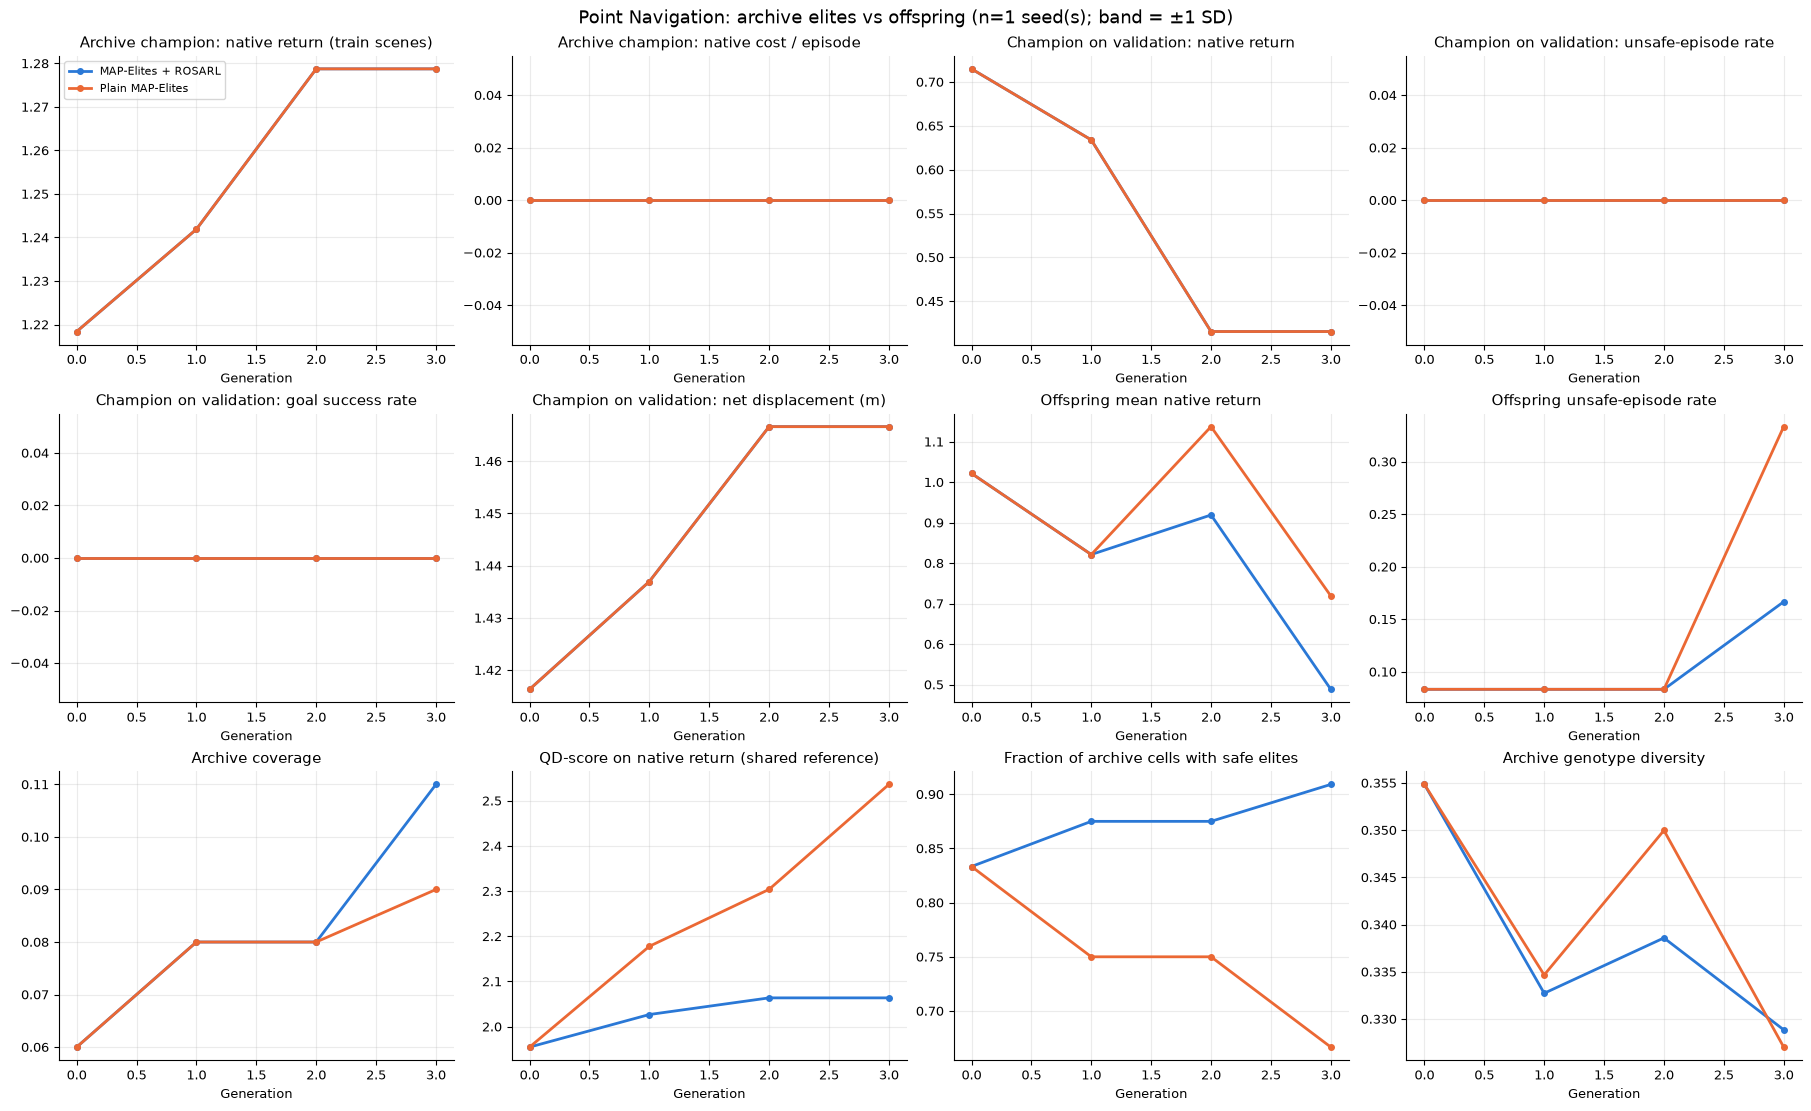

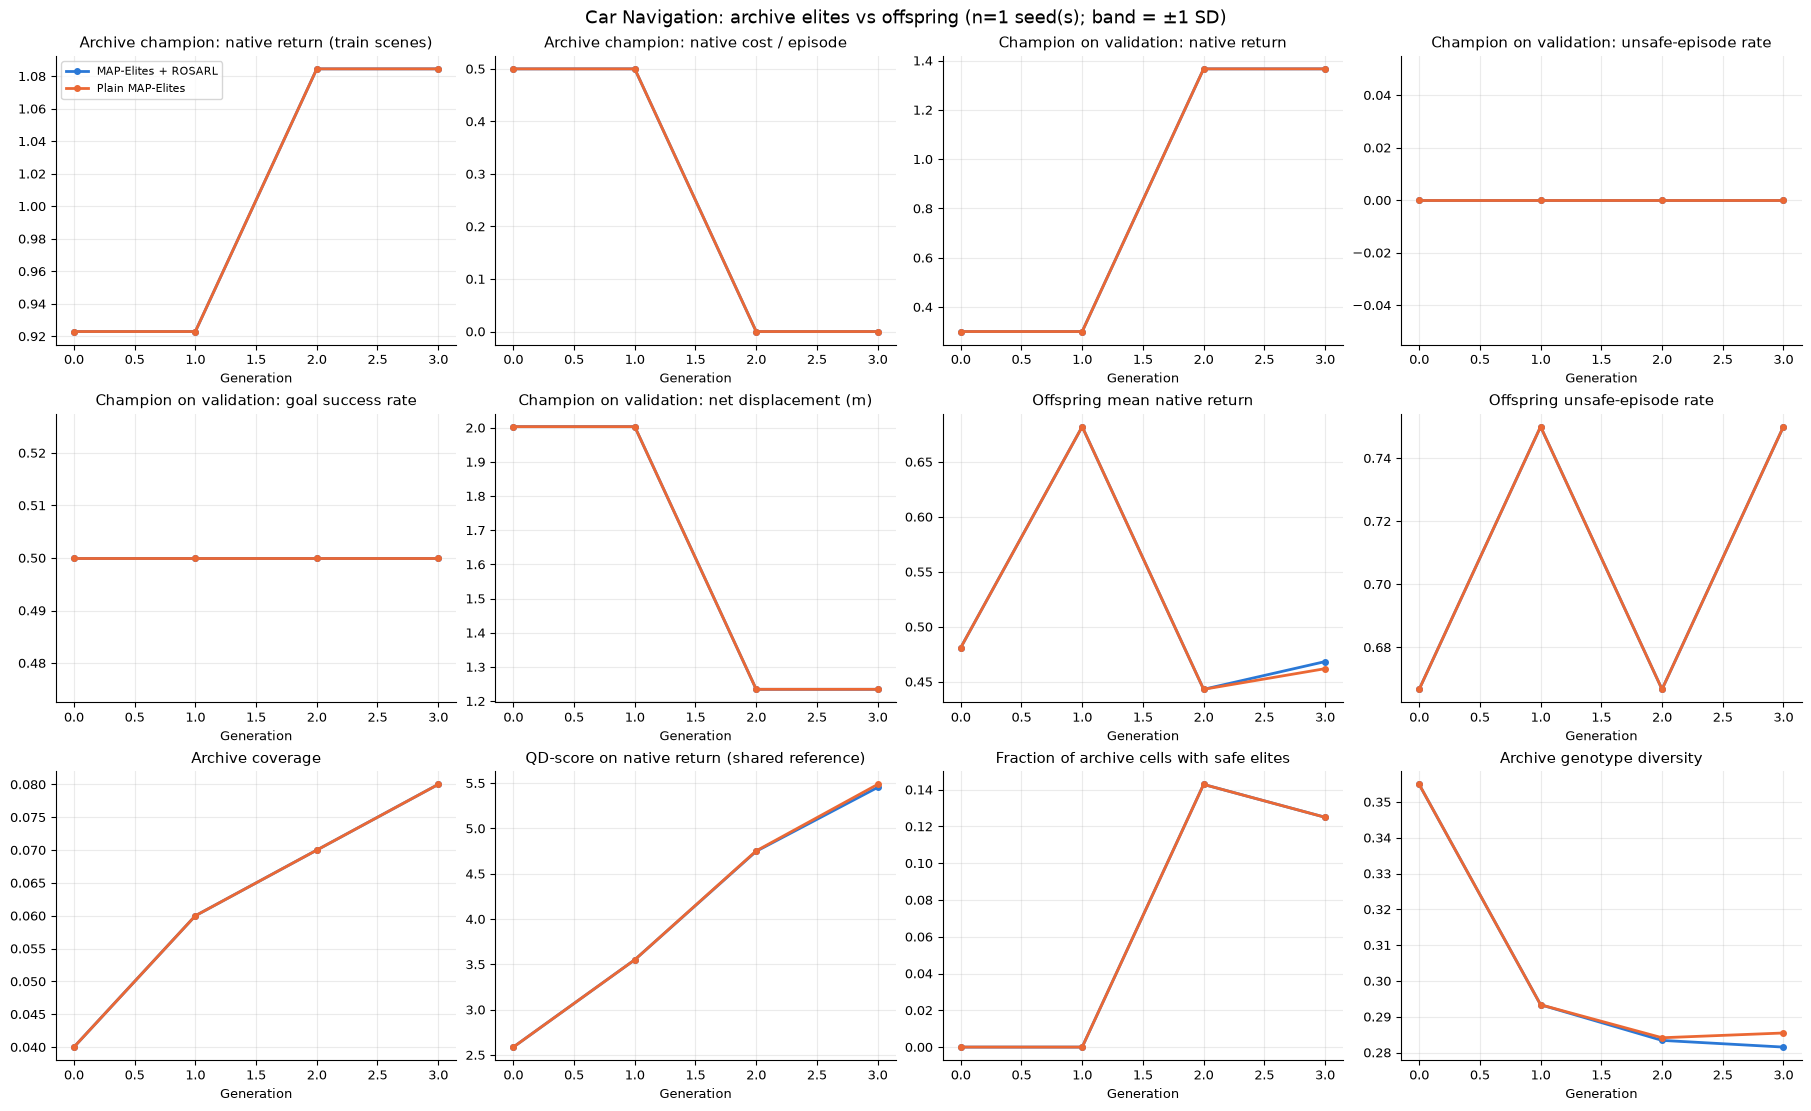

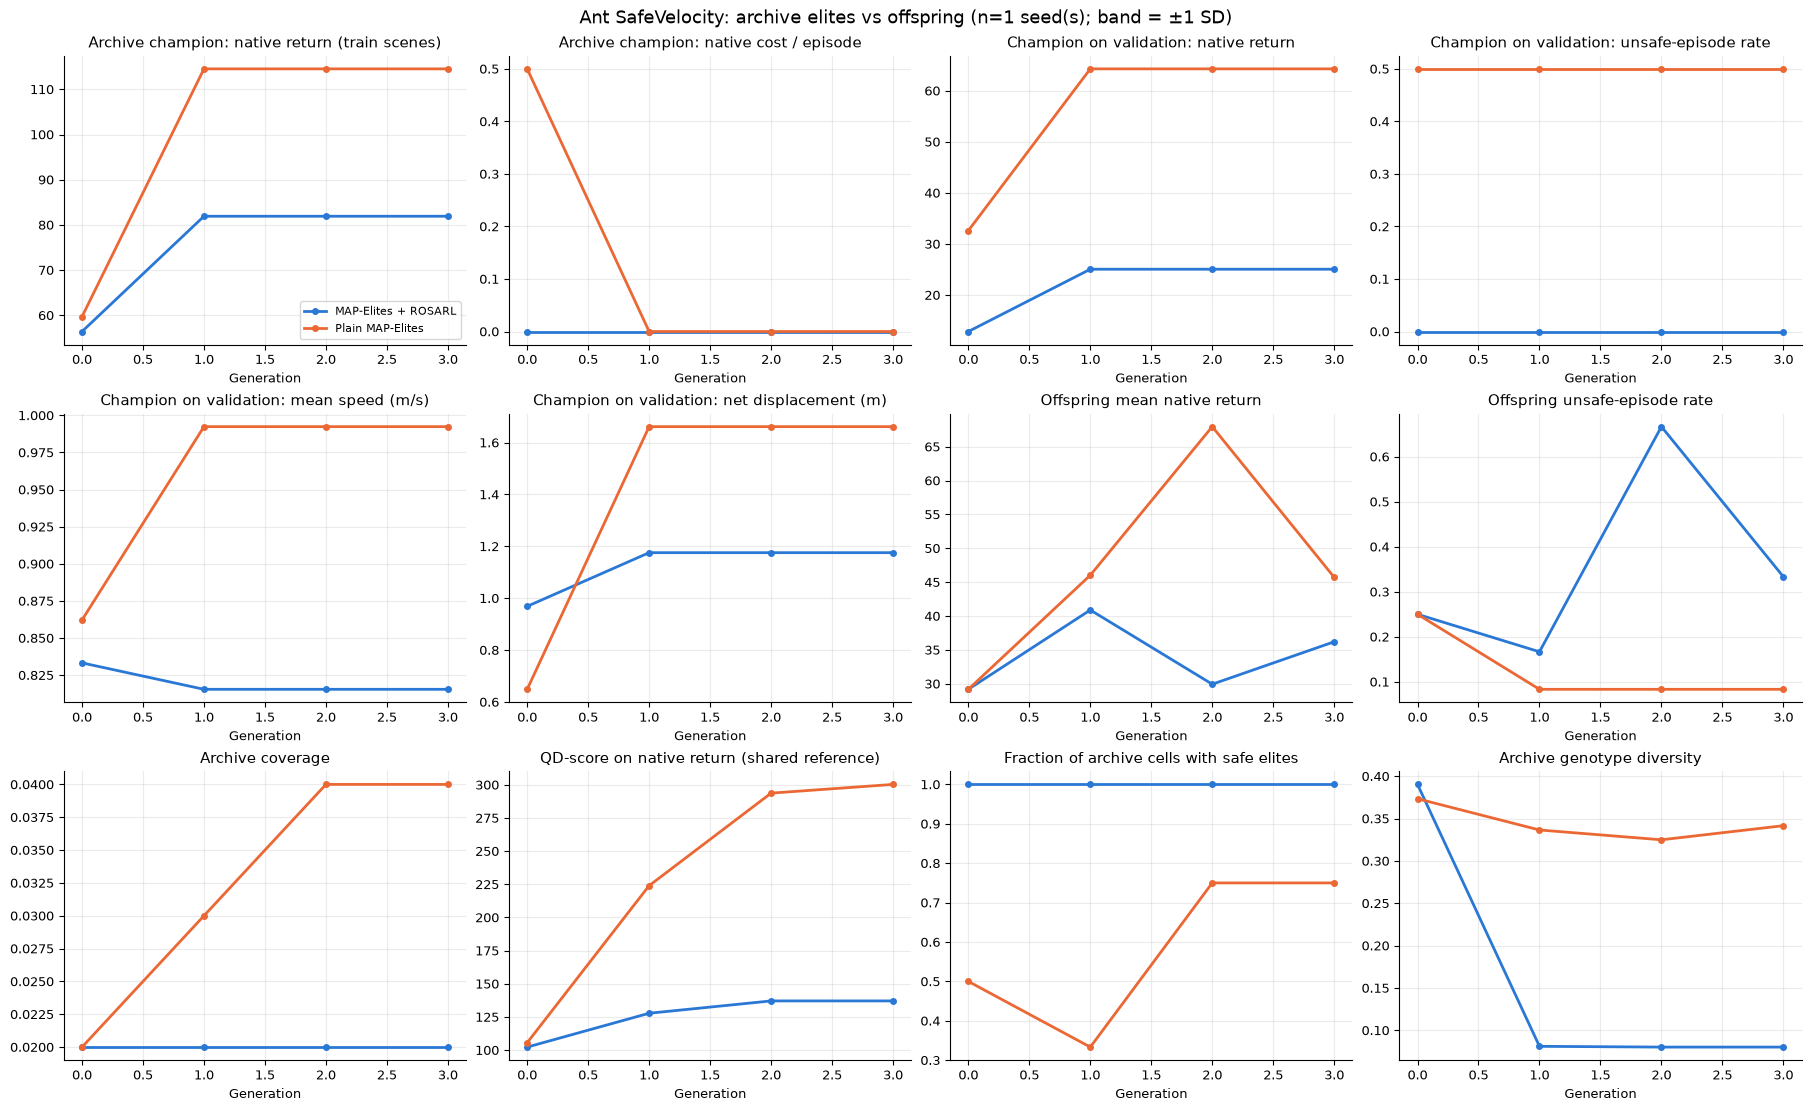

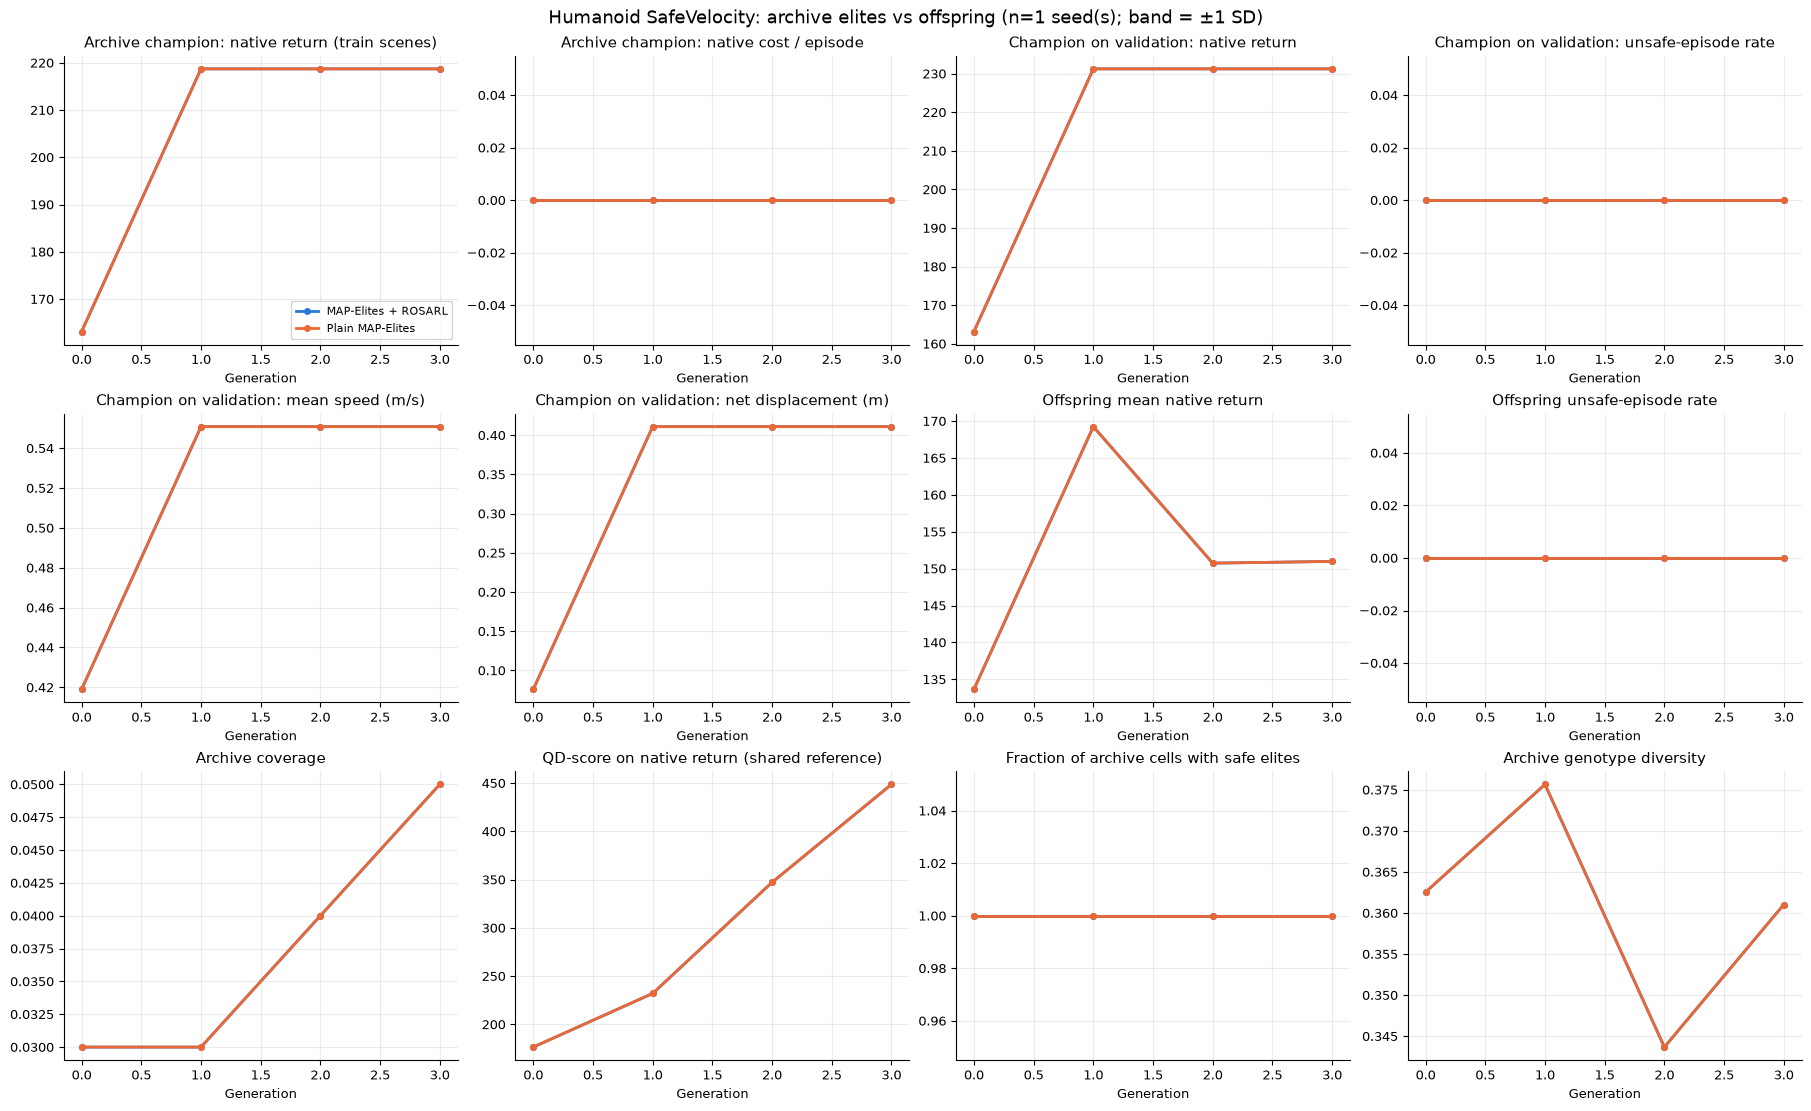

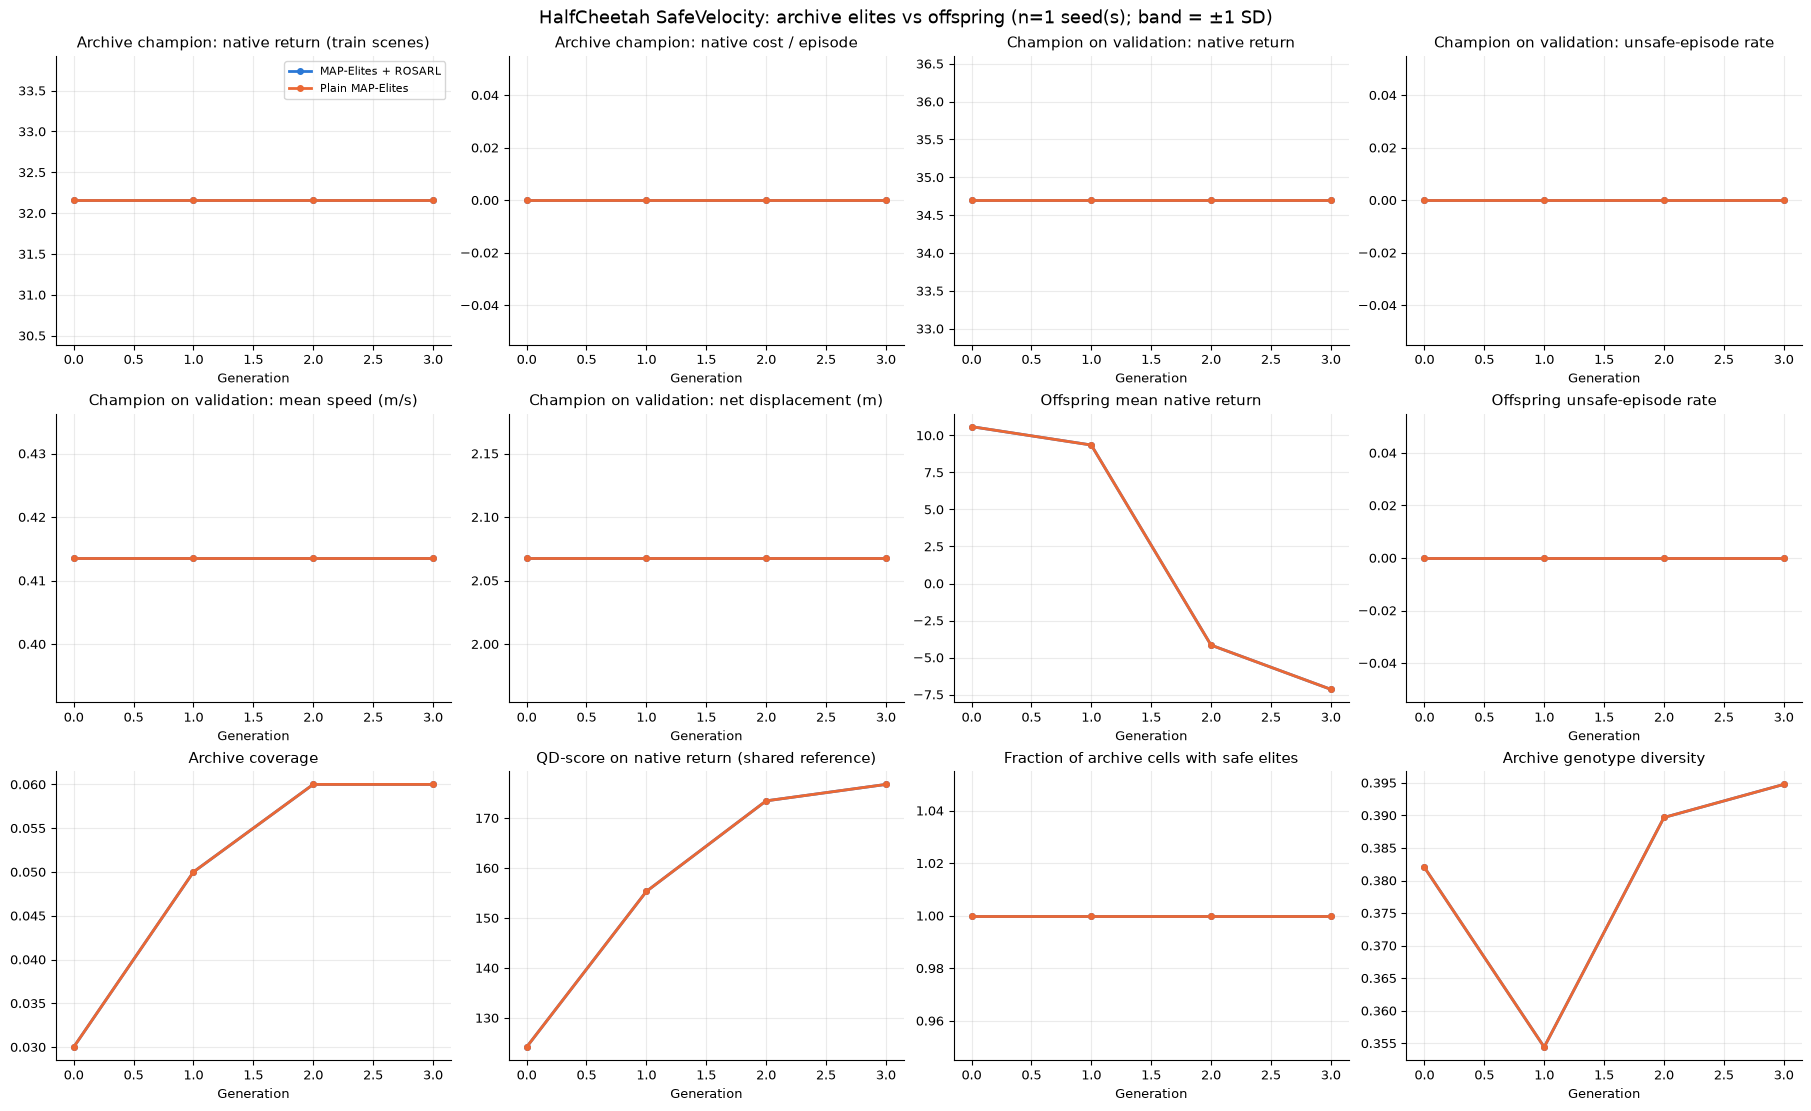

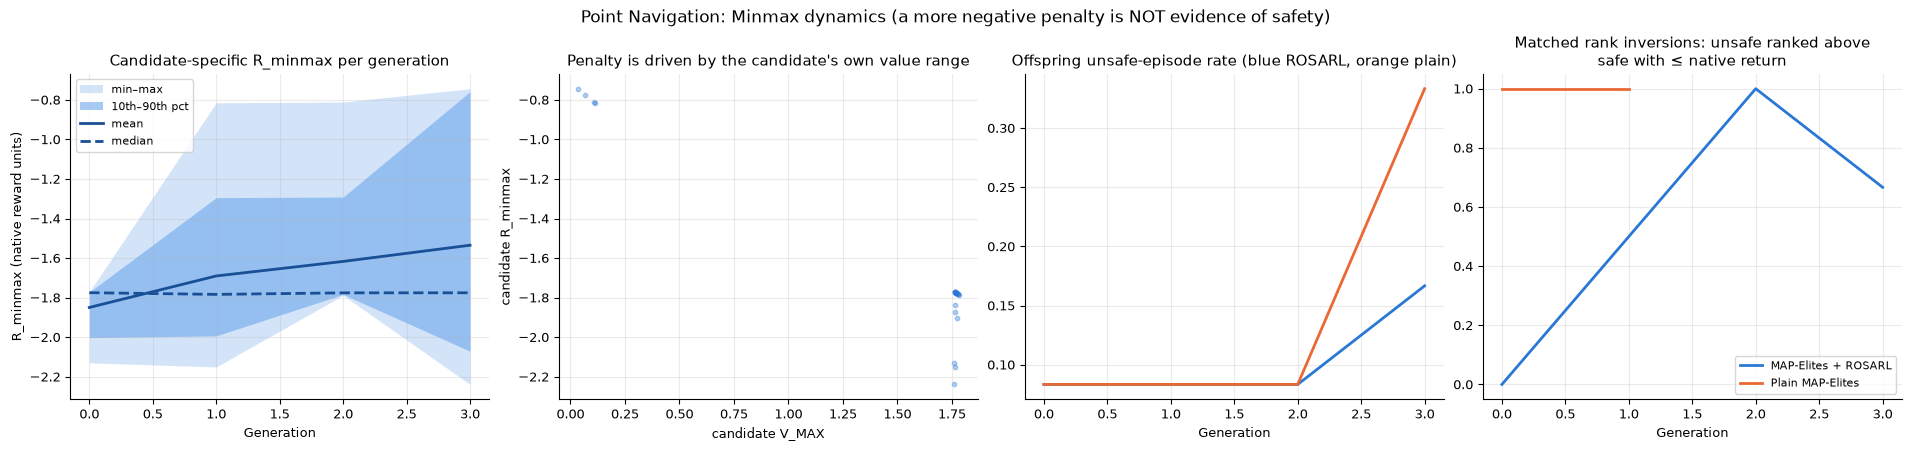

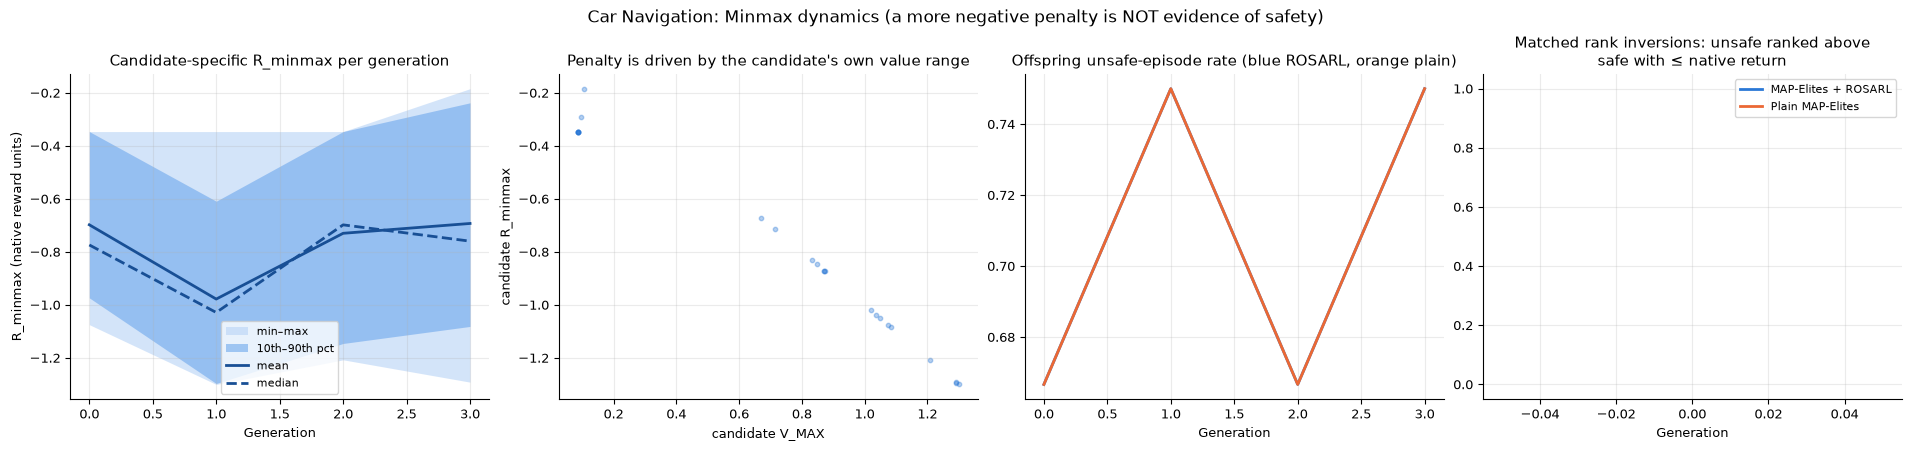

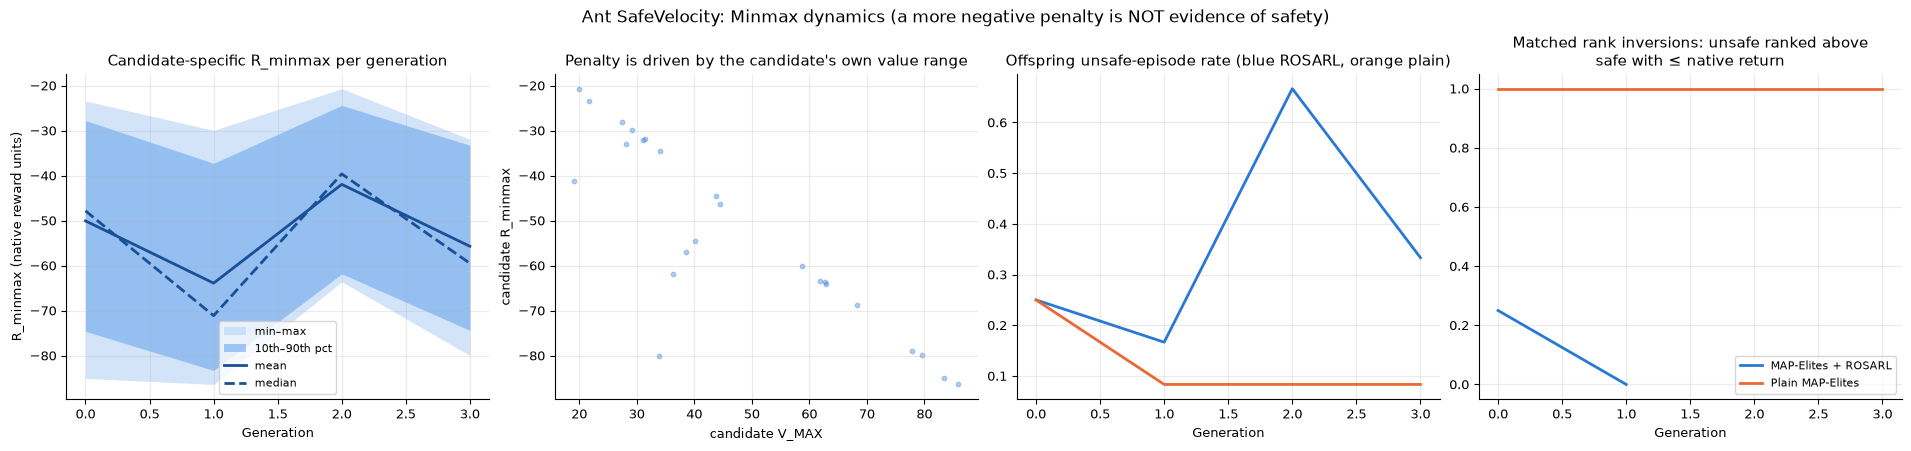

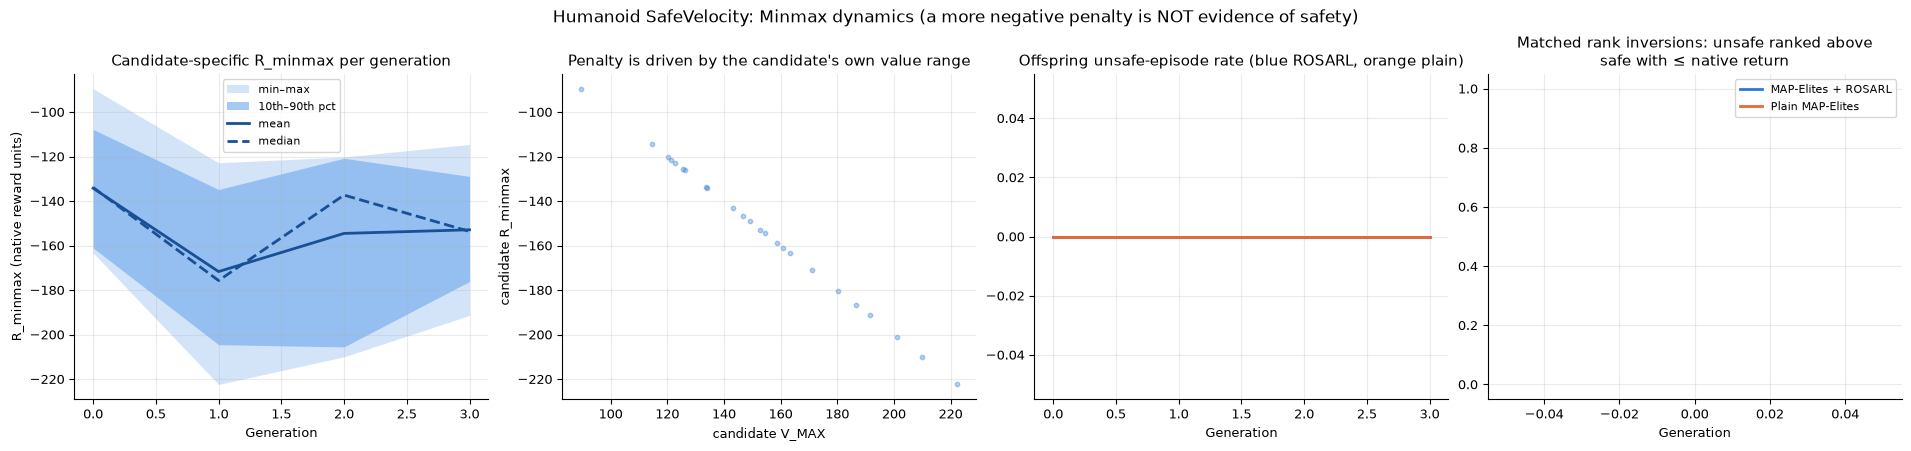

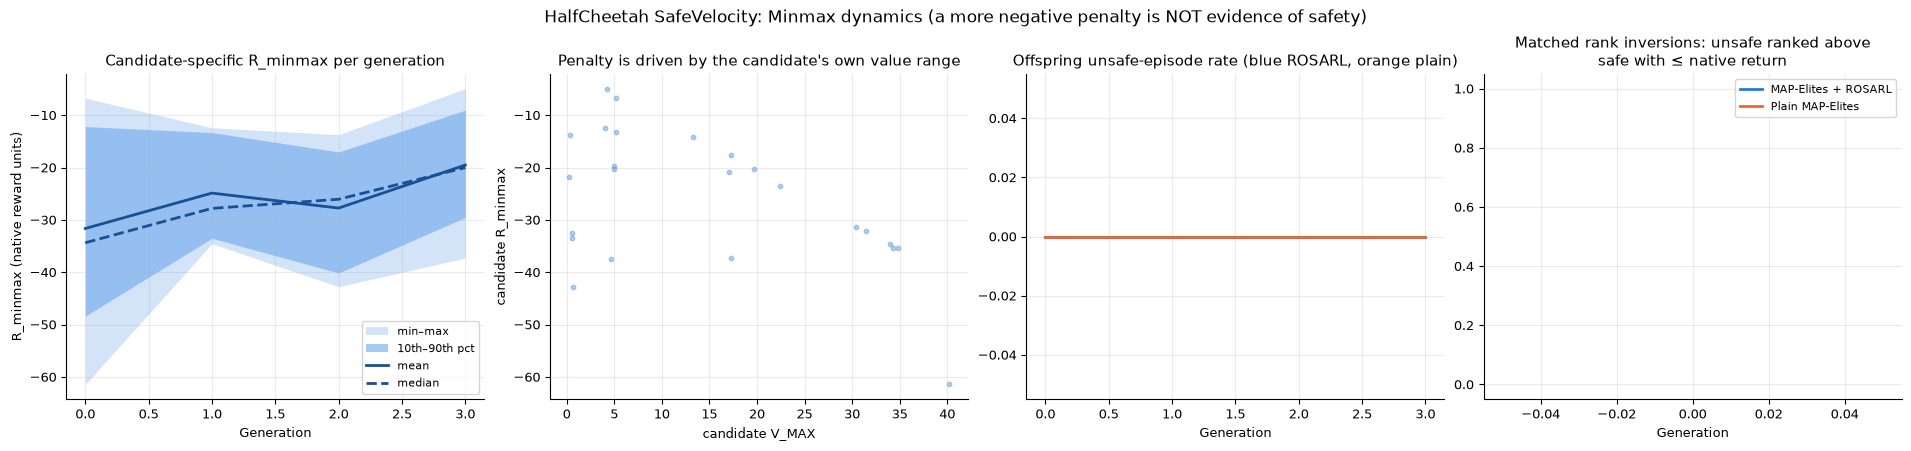

In [11]:
COLORS = {METHODS[0]: '#2a78d6', METHODS[1]: '#eb6834'}   # fixed per method, never by rank
OUT = RESULTS_DIR / 'figures'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': .25, 'lines.linewidth': 2, 'font.size': 9})


def slug(task):
    return task.lower().replace(' ', '_')


def draw_metric(ax, df, metric, label):
    """Mean across training seeds; band = +-1 sample SD across seeds (only when n_seeds>1)."""
    for method in METHODS:
        g = df[df.method == method].dropna(subset=[metric]).groupby('generation')[metric]
        if g.ngroups == 0:
            continue
        m, s = g.mean(), g.std()
        ax.plot(m.index, m.values, color=COLORS[method], label=method, marker='o' if len(m) < 15 else None, ms=4)
        if s.notna().any():
            ax.fill_between(m.index, m - s.fillna(0), m + s.fillna(0), color=COLORS[method], alpha=.15, lw=0)
    ax.set_title(label)
    ax.set_xlabel('Generation')


def plot_training(history):
    for task in history.task.unique():
        df = history[history.task == task]
        kind = TASKS[task][0]
        panels = [('best_fitness_raw_return', 'Archive champion: native return (train scenes)'),
                  ('best_fitness_cost', 'Archive champion: native cost / episode'),
                  ('val_return_raw', 'Champion on validation: native return'),
                  ('val_unsafe', 'Champion on validation: unsafe-episode rate'),
                  ('val_success' if kind == 'navigation' else 'val_mean_speed',
                   'Champion on validation: goal success rate' if kind == 'navigation'
                   else 'Champion on validation: mean speed (m/s)'),
                  ('val_net_displacement', 'Champion on validation: net displacement (m)'),
                  ('off_raw_return', 'Offspring mean native return'),
                  ('off_unsafe_rate', 'Offspring unsafe-episode rate'),
                  ('coverage', 'Archive coverage'),
                  ('qd_score_raw', 'QD-score on native return (shared reference)'),
                  ('safe_cell_fraction', 'Fraction of archive cells with safe elites'),
                  ('genotype_diversity', 'Archive genotype diversity')]
        fig, axes = plt.subplots(3, 4, figsize=(18, 11), constrained_layout=True)
        for ax, (metric, label) in zip(axes.flat, panels):
            draw_metric(ax, df, metric, label)
        axes.flat[0].legend(loc='best', fontsize=8)
        fig.suptitle(f'{task}: archive elites vs offspring (n={df.seed.nunique()} seed(s); band = ±1 SD)', fontsize=13)
        fig.savefig(OUT / f'{slug(task)}_training.png', dpi=160)
        plt.show()
        plt.close(fig)


def plot_penalties(history, penalties):
    for task in history.task.unique():
        df = history[(history.task == task) & (history.method == METHODS[0])]
        agg = df.groupby('generation')[['pen_mean', 'pen_median', 'pen_min', 'pen_max', 'pen_p10', 'pen_p90',
                                        'off_unsafe_rate', 'matched_inversion_rate', 'inversion_rate']].mean()
        x = agg.index.to_numpy(float)
        fig, axes = plt.subplots(1, 4, figsize=(19, 4.4), constrained_layout=True)
        ax = axes[0]
        ax.fill_between(x, agg.pen_min, agg.pen_max, color='#b7d3f6', alpha=.6, lw=0, label='min–max')
        ax.fill_between(x, agg.pen_p10, agg.pen_p90, color='#6da7ec', alpha=.6, lw=0, label='10th–90th pct')
        ax.plot(x, agg.pen_mean, color='#184f95', label='mean')
        ax.plot(x, agg.pen_median, color='#184f95', ls='--', label='median')
        ax.set_title('Candidate-specific R_minmax per generation')
        ax.set_ylabel('R_minmax (native reward units)')
        ax.legend(fontsize=8)
        p = penalties[penalties.task == task]
        ax = axes[1]
        ax.scatter(p.v_max, p.penalty, s=10, alpha=.35, color='#2a78d6')
        ax.set_xlabel('candidate V_MAX')
        ax.set_ylabel('candidate R_minmax')
        ax.set_title('Penalty is driven by the candidate\'s own value range')
        ax = axes[2]
        ax.plot(x, agg.off_unsafe_rate, color='#2a78d6')
        h = history[(history.task == task) & (history.method == METHODS[1])].groupby('generation').off_unsafe_rate.mean()
        ax.plot(h.index, h.values, color='#eb6834')
        ax.set_title('Offspring unsafe-episode rate (blue ROSARL, orange plain)')
        ax.set_xlabel('Generation')
        ax = axes[3]
        for method in METHODS:
            g = history[(history.task == task) & (history.method == method)].groupby('generation').matched_inversion_rate.mean()
            ax.plot(g.index, g.values, color=COLORS[method], label=method)
        ax.set_ylim(-.05, 1.05)
        ax.set_title('Matched rank inversions: unsafe ranked above\nsafe with ≤ native return')
        ax.legend(fontsize=8)
        for a in (axes[0], axes[3]):
            a.set_xlabel('Generation')
        fig.suptitle(f'{task}: Minmax dynamics (a more negative penalty is NOT evidence of safety)', fontsize=12)
        fig.savefig(OUT / f'{slug(task)}_minmax.png', dpi=160)
        plt.show()
        plt.close(fig)


plot_training(HISTORY)
plot_penalties(HISTORY, PENALTIES)


## 11. Held-out evaluation (unseen scenes, identical for both arms) and validation summary
Navigation and velocity metrics are reported separately and never pooled.


=== NAVIGATION tasks: held-out comparison ===


,task,metric,MAP-Elites + ROSARL,Plain MAP-Elites,paired diff (ROSARL−plain),n_seeds
0,Point Navigation,goal success rate,0.250 (n=1),0.250 (n=1),"+0.000 (no CI, n=1)",1
1,Point Navigation,collision (hazard) rate,0.250 (n=1),0.250 (n=1),"+0.000 (no CI, n=1)",1
2,Point Navigation,timeout rate,0.500 (n=1),0.500 (n=1),"+0.000 (no CI, n=1)",1
3,Point Navigation,native return,0.994 (n=1),0.994 (n=1),"+0.000 (no CI, n=1)",1
4,Point Navigation,episode length,79.250 (n=1),79.250 (n=1),"+0.000 (no CI, n=1)",1
5,Point Navigation,distance travelled (m),1.508 (n=1),1.508 (n=1),"+0.000 (no CI, n=1)",1
6,Point Navigation,final distance to goal (m),0.694 (n=1),0.694 (n=1),"+0.000 (no CI, n=1)",1
7,Car Navigation,goal success rate,0.250 (n=1),0.250 (n=1),"+0.000 (no CI, n=1)",1
8,Car Navigation,collision (hazard) rate,0.500 (n=1),0.500 (n=1),"+0.000 (no CI, n=1)",1
9,Car Navigation,timeout rate,0.250 (n=1),0.250 (n=1),"+0.000 (no CI, n=1)",1



=== VELOCITY tasks: held-out comparison ===


,task,metric,MAP-Elites + ROSARL,Plain MAP-Elites,paired diff (ROSARL−plain),n_seeds
14,Ant SafeVelocity,native return,68.493 (n=1),55.522 (n=1),"+12.971 (no CI, n=1)",1
15,Ant SafeVelocity,native accumulated cost,0.250 (n=1),0.250 (n=1),"+0.000 (no CI, n=1)",1
16,Ant SafeVelocity,safe-step fraction,0.997 (n=1),0.997 (n=1),"+0.000 (no CI, n=1)",1
17,Ant SafeVelocity,mean cost-relevant speed (m/s),1.020 (n=1),0.906 (n=1),"+0.114 (no CI, n=1)",1
18,Ant SafeVelocity,speed-limit violations / episode,0.250 (n=1),0.250 (n=1),"+0.000 (no CI, n=1)",1
19,Ant SafeVelocity,distance travelled (m),4.694 (n=1),3.756 (n=1),"+0.937 (no CI, n=1)",1
20,Ant SafeVelocity,native termination (fall) rate,0.250 (n=1),0.250 (n=1),"+0.000 (no CI, n=1)",1
21,Ant SafeVelocity,episode length,91.500 (n=1),84.500 (n=1),"+7.000 (no CI, n=1)",1
22,Humanoid SafeVelocity,native return,219.788 (n=1),219.788 (n=1),"+0.000 (no CI, n=1)",1
23,Humanoid SafeVelocity,native accumulated cost,0.000 (n=1),0.000 (n=1),"+0.000 (no CI, n=1)",1


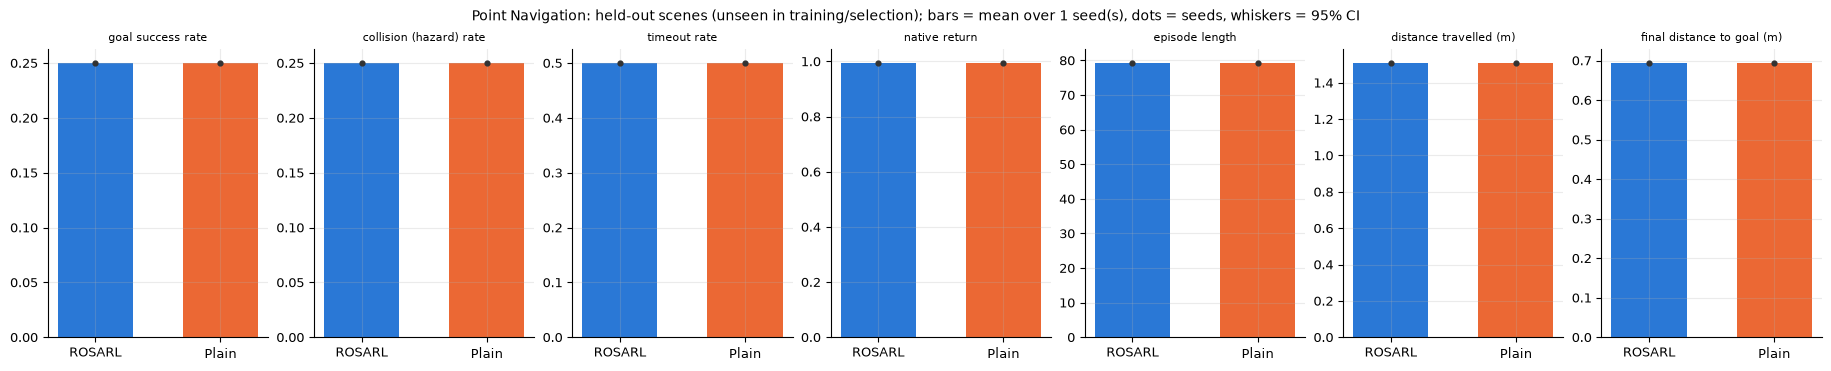

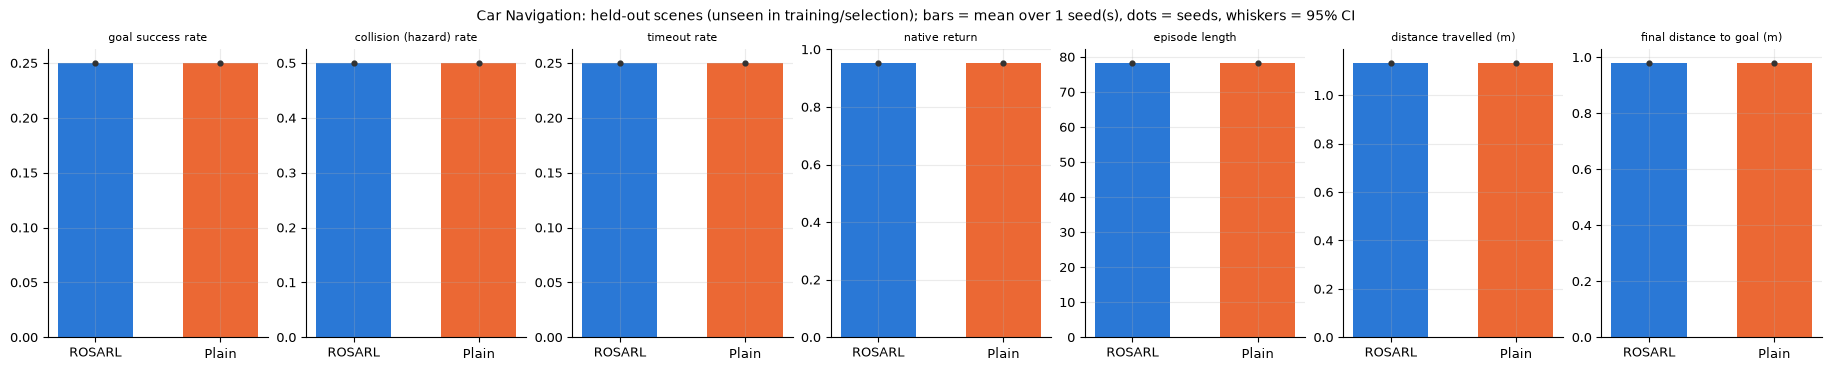

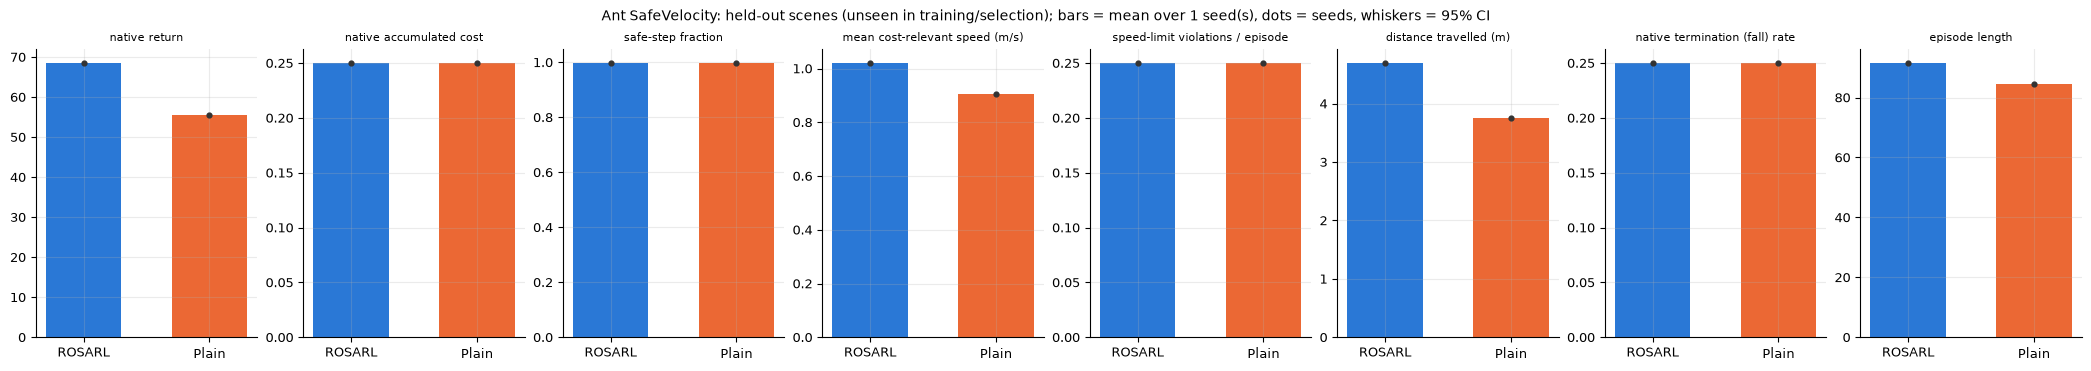

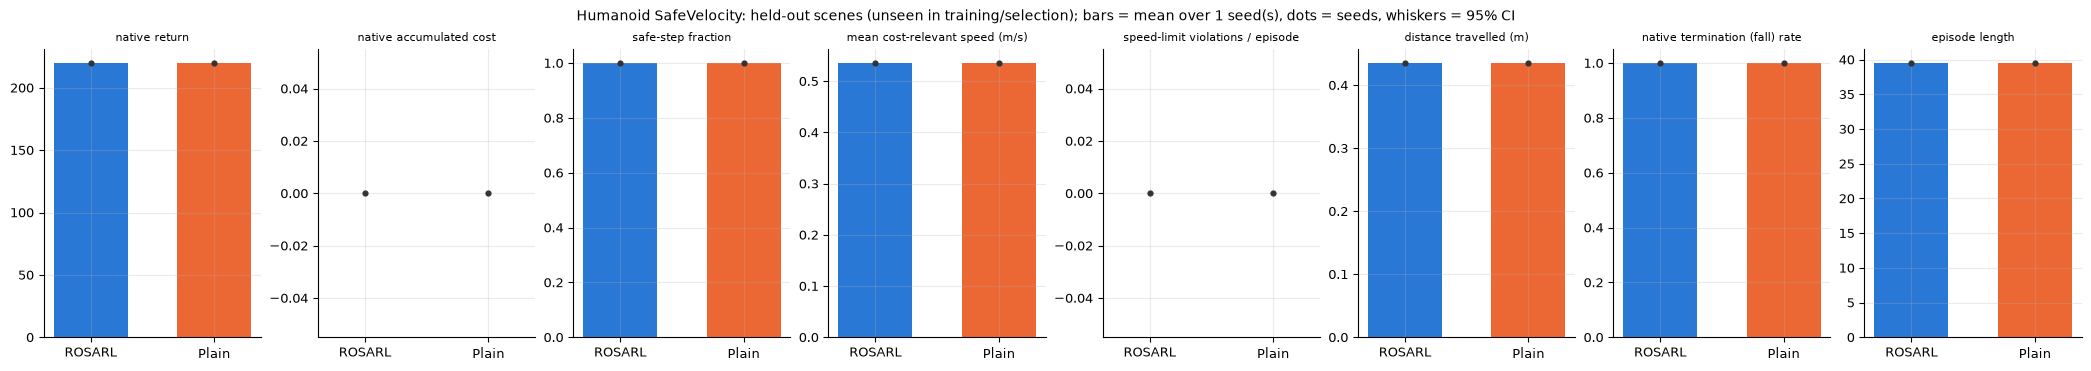

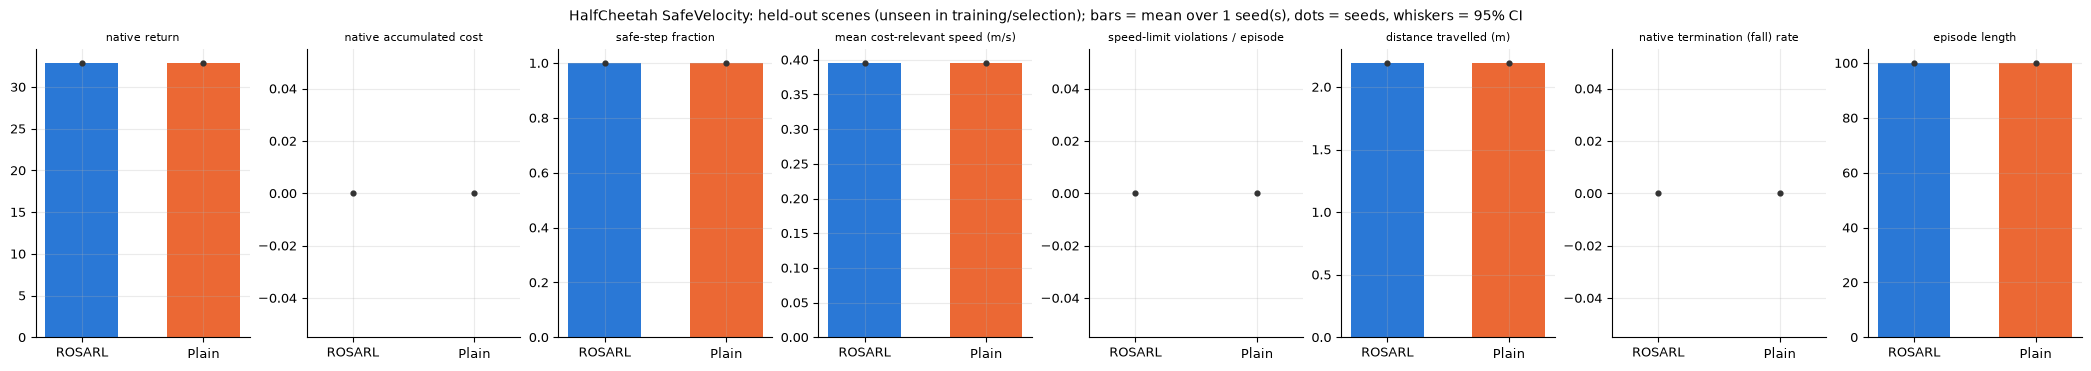

NOTE: fewer than 3 training seeds -> descriptive only; no inferential claim is supported.

=== Validation summary (PASS / FAIL / INFO / NOT TESTED) ===


status                                 FAIL  INFO  PASS
section      task                                      
Environment  Ant Navigation               0     0    10
             Ant SafeVelocity             0     0    12
             Car Navigation               0     0    11
             HalfCheetah SafeVelocity     0     0    12
             Humanoid SafeVelocity        1     0    11
             Point Navigation             1     0     0
QDax archive -                            0     0     4
ROSARL unit  -                            0     1    16
Training     Ant Navigation seed 1        1     0     0

Saved CSVs and figures to c:\Users\mthom\Downloads\Claude_Pro_Project\qdax_rosarl_audit\safeqd_work\safe_qd_results_smoke


In [12]:
try:
    from scipy.stats import t as _t
    t_quantile = lambda n: float(_t.ppf(.975, n - 1))
except ImportError:
    t_quantile = lambda n: {2: 12.71, 3: 4.30, 4: 3.18, 5: 2.78, 6: 2.57, 7: 2.45, 8: 2.36, 9: 2.31, 10: 2.26}.get(n, 2.0)

NAV_METRICS = [('success', 'goal success rate'), ('unsafe', 'collision (hazard) rate'),
               ('timeout', 'timeout rate'), ('return_raw', 'native return'), ('steps', 'episode length'),
               ('path_length', 'distance travelled (m)'), ('final_distance', 'final distance to goal (m)')]
VEL_METRICS = [('return_raw', 'native return'), ('cost', 'native accumulated cost'),
               ('safe_fraction', 'safe-step fraction'), ('mean_speed', 'mean cost-relevant speed (m/s)'),
               ('unsafe_steps', 'speed-limit violations / episode'), ('path_length', 'distance travelled (m)'),
               ('fell', 'native termination (fall) rate'), ('steps', 'episode length')]


def heldout_table(heldout):
    """Unit of replication = training seed: average episodes within a seed first, then
    mean / sample SD / 95% t-CI across seeds, plus the paired ROSARL - plain difference."""
    h = heldout.copy()
    h['timeout'] = h.termination.isin(['horizon', 'native_truncation']).astype(float)
    h['fell'] = (h.termination == 'native_terminal').astype(float)
    rows = []
    for task in h.task.unique():
        kind = TASKS[task][0]
        per_seed = h[h.task == task].groupby(['method', 'seed']).mean(numeric_only=True)
        for metric, label in (NAV_METRICS if kind == 'navigation' else VEL_METRICS):
            row = dict(task=task, metric=label)
            for method in METHODS:
                v = per_seed.loc[method][metric].to_numpy(float)
                n = len(v)
                half = t_quantile(n) * v.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan
                row[method] = f'{v.mean():.3f} ± {half:.3f}' if n > 1 else f'{v.mean():.3f} (n=1)'
            d = (per_seed.loc[METHODS[0]][metric] - per_seed.loc[METHODS[1]][metric]).to_numpy(float)
            row['paired diff (ROSARL−plain)'] = (f'{d.mean():+.3f} ± {t_quantile(len(d)) * d.std(ddof=1) / np.sqrt(len(d)):.3f}'
                                                 if len(d) > 1 else f'{d.mean():+.3f} (no CI, n=1)')
            row['n_seeds'] = len(d)
            rows.append(row)
    return pd.DataFrame(rows)


def plot_heldout(heldout):
    h = heldout.copy()
    h['timeout'] = h.termination.isin(['horizon', 'native_truncation']).astype(float)
    h['fell'] = (h.termination == 'native_terminal').astype(float)
    for task in h.task.unique():
        kind = TASKS[task][0]
        metrics = NAV_METRICS if kind == 'navigation' else VEL_METRICS
        fig, axes = plt.subplots(1, len(metrics), figsize=(2.6 * len(metrics), 3.6), constrained_layout=True)
        per_seed = h[h.task == task].groupby(['method', 'seed']).mean(numeric_only=True)
        for ax, (metric, label) in zip(axes, metrics):
            for i, method in enumerate(METHODS):
                v = per_seed.loc[method][metric].to_numpy(float)
                ax.bar(i, v.mean(), width=.6, color=COLORS[method])
                ax.scatter(np.full(len(v), i), v, color='#333', s=12, zorder=3)
                if len(v) > 1:
                    ax.errorbar(i, v.mean(), yerr=t_quantile(len(v)) * v.std(ddof=1) / np.sqrt(len(v)),
                                color='#333', capsize=4)
            ax.set_xticks([0, 1], ['ROSARL', 'Plain'])
            ax.set_title(label, fontsize=8)
        fig.suptitle(f'{task}: held-out scenes (unseen in training/selection); bars = mean over '
                     f'{h[h.task == task].seed.nunique()} seed(s), dots = seeds, whiskers = 95% CI', fontsize=10)
        fig.savefig(OUT / f'{slug(task)}_heldout.png', dpi=160)
        plt.show()
        plt.close(fig)


if len(HELDOUT):
    TABLE = heldout_table(HELDOUT)
    for kind in ('navigation', 'velocity'):   # never pooled across task families
        sub = TABLE[TABLE.task.map(lambda t: TASKS[t][0]) == kind]
        if len(sub):
            print(f'\n=== {kind.upper()} tasks: held-out comparison ===')
            display(sub)
    plot_heldout(HELDOUT)
    if HELDOUT.seed.nunique() < 3:
        print('NOTE: fewer than 3 training seeds -> descriptive only; no inferential claim is supported.')
    TABLE.to_csv(RESULTS_DIR / 'heldout_summary.csv', index=False)
HISTORY.to_csv(RESULTS_DIR / 'generation_metrics.csv', index=False)
HELDOUT.to_csv(RESULTS_DIR / 'heldout_episodes.csv', index=False)
PENALTIES.to_csv(RESULTS_DIR / 'candidate_penalties.csv', index=False)
VALIDATION = pd.DataFrame(TEST_RESULTS)
VALIDATION.to_csv(RESULTS_DIR / 'validation_tests.csv', index=False)
print('\n=== Validation summary (PASS / FAIL / INFO / NOT TESTED) ===')
display(VALIDATION.pivot_table(index=['section', 'task'], columns='status', values='test', aggfunc='count', fill_value=0))
print('Saved CSVs and figures to', RESULTS_DIR)


## 12. Interpretation guide and limitations (read before writing results)
1. **Is this ROSARL?** It is an *evolutionary adaptation*. Faithful: bound initialisation, update rules, the
   min(R_MIN, V_MIN−V_MAX) estimate, replacement (not addition) on unsafe transitions, absorbing unsafe states.
   Different: (a) $V$ is the candidate's own undiscounted Monte-Carlo return of the *native* reward, not a learned
   critic; (b) bounds are reset per candidate instead of growing over one agent's lifetime; (c) the penalty is the
   candidate's final batch estimate applied in hindsight. Because a genome is fixed during evaluation, hindsight
   replacement gives exactly the fitness that in-loop replacement would give — rewards only reach learning through
   fitness in MAP-Elites — so (c) is harmless; (a)+(b) are not.
2. **Guarantee actually provided.** For an unsafe-terminated episode, the replaced return is
   $\le V^{(i)}_{\min}-r_{\rm unsafe}\le -r_{\rm unsafe}$ (unit-tested). Hence an unsafe outcome ranks below any safe
   candidate whose mean return exceeds that value — e.g. always on Ant/Humanoid velocity (positive healthy reward),
   but **not** against safe navigation candidates with negative return. The original ROSARL guarantee uses the
   MDP-wide $V_{\min},V_{\max}$; per-candidate bounds are narrower, so cross-candidate ranking is weaker.
   The *matched rank-inversion* plot measures this on real data.
3. **Penalty magnitude** tracks the candidate's own $V_{\max}$ (scatter plot): better candidates receive harsher
   penalties. More negative mean penalties therefore often mean *better returns*, not more safety.
4. **Velocity termination** makes the unsafe state absorbing for both arms, so plain MAP-Elites also loses future
   reward after a violation (an implicit safety signal shared by both arms). The ROSARL arm differs only in the
   reward of the violating transition.
5. **Movement / task feasibility** — see the movement table: Humanoid falls in ≈30 steps under every controller
   tried, HalfCheetah stays far below its speed limit, Ant-Goal rarely reaches goals. On such tasks the arms can only
   differ if violations occur; report them as *non-informative*, not as "no difference".
6. **Audit pilot (3 seeds, 20 gens, pop 16, 3 training layouts; Point-Goal and Ant-Velocity).** ROSARL changed
   *selection*: offspring unsafe rate 0.29 vs 0.43 (Point) and 0.18 vs 0.22 (Ant) at the final generation;
   matched rank inversions 0.38 vs 1.00. It did **not** produce a detectable held-out difference (Point collision
   0.50 vs 0.47, paired diff +0.03 ± 0.32; Ant violations 0.03 vs 0.03). Champions of *both* arms collided in ≈50% of
   unseen layouts: with 3 training layouts, safety does not generalise — hence more layouts in the presets.
7. **Statistics:** the replication unit is the training seed. Report mean ± 95% t-CI over ≥5 seeds and the paired
   difference; with 1 seed results are descriptive only.